# Comps and valuation

Steps 4-7 of the mentor's recipe for getting comps, building on `comp_universe_and_facets.ipynb` (steps 1-3):

4. **Suggest comps** for a target (an LLM or any other way).
5. **Profiles:** construct a company profile for the target and the comps. Here a target's **profile** is its collection of comps. A company's facets are its **business-model characteristics** (descriptive characteristics), not its profile.
6. **Score each comp** between 0 and 1: is it a good or bad comp? (an LLM, embeddings and cosine similarity, or any other way).
7. **Estimate:** a suitably weighted average of the comps' EV/EBITDA.

Plus the recipe's balanced 70/30 training/holdout split. The recipe's evals (manual review of target-comp pairs with a rubric) come later, in a separate notebook; `judgments.csv` (section 3) is the pair table it will start from.

How the recipe maps onto this notebook (decided 2026-10-25):

| section | recipe | here | status |
|---|---|---|---|
| 1 | split | 70/30, stratified on SIC2 (the earlier version stratified on company size) | built |
| 2 | 4. suggest comps, 5. profiles | embedding cosine similarity on the facets; each target's profile is its candidates, the top k or z ≥ 2 | built |
| 3 | 6. good or bad, 0-1 | **the model:** an LLM (Claude Haiku 5.5) marks each z ≥ 2 candidate good (1) or bad (0). Its prompt and any fitted weights are developed on the training firms. | built |
| 4 | 4 again, without embeddings | the LLM suggests comps directly from the whole training pool; and same-SIC peers, with no model at all | built |
| 5 | LLM then cosine | cosine reranks and weights the direct LLM selections | built |
| 6 | 7. weighted EV/EBITDA | the estimate against the actual multiples, for every way of finding comps, and against no matching | built |
| 7 | (extension) which facets drive the score | per-facet separation, lift and heatmaps, including company size (F9), which is not in the similarity | built |
| 8 | (extension) what company size does | error by size category, size gap against the LLM's verdict, comps restricted by size | built |

**"Training" here means the 373 firms we may look at while developing, not a fitted model.** Nothing is fitted yet: every way of finding comps is run on every training target, and its estimates are compared with the actual multiples. The 160 holdout firms are kept for one final test.

Record each decision in its section (and in `v0/README.md`) before writing that section's code.

Runs in the `qual2cast` kernel (Python 3.14), which has `sentence-transformers`.

> **Status (2026-10-27): this is the main comps notebook and the updated baseline model.** The previous baseline, which stratified the split on company size and used the original ten showcase targets, is kept in [`history/comps_and_valuation_size_stratified.ipynb`](history/comps_and_valuation_size_stratified.ipynb); its outputs are in `outputs-local/comps/`. What differs here:
> - the **ten showcase targets are the business-structure pilot's** (PCTY, WEN, CSL, AFG, BOC, NWSA, AZZ, BBCP, BUKS, SNFC.A), listed with the reason each was picked right below;
> - the **split is stratified on SIC2** (section 1), so company size (F9) varies freely and can be tested (sections 7-8); 271 of the 373 training firms are the same as before;
> - the **judge and the direct picks were re-run** with Claude Haiku 5.5 on this split;
> - new **section 7** (facet contribution, including F9), **section 8** (what company size does) and **section 9** (choosing the golden-set targets).
>
> All outputs of this notebook are in `outputs-local/comps_pilot_targets/` (see the README there), not in `comps/`: `judge_comps.py` and `suggest_comps.py` default to the latest candidates run in `comps/`, so a run written there would silently redirect them. The split decision is a proposal until the team reviews it.


## The ten showcase targets, and why these ten

The showcase set is the **business-structure pilot's ten targets** (`TARGETS` in `v0/notebooks/business_structure_eval.ipynb`, which this notebook reuses so the v0 comps pipeline and the pilot are looked at on the same companies). They were picked **deliberately as source challenges** from the pilot's 40-company development set, to test whether a company is one business or several, using official company pages. They are **not a random sample**, so results on them show how the method behaves on hard cases, not how accurate it is overall.

| ticker | company | what it was picked to test | pilot's split result (current lines → business groups; exited lines) | source |
|---|---|---|---|---|
| PCTY | Paylocity | **related products** inside one business | one business (1 line) | [paylocity.com](https://www.paylocity.com/) |
| WEN | The Wendy's Company | **related products** inside one business | one business (1 line) | [Wendy's franchise FAQs](https://www.wendys.com/franchising/franchise-faqs) |
| CSL | Carlisle Companies | a **completed exit** (Carlisle Interconnect Technologies sale) | one business (1 line); 3 exited | [Carlisle press release](https://www.carlisle.com/investors/news/press-release-details/2024/Carlisle-Companies-Completes-Sale-of-Carlisle-Interconnect-Technologies/default.aspx) |
| AFG | American Financial Group | a **completed exit** (the annuity business sale) | one business (1 line); 2 exited | [AFG news release](https://www.afginc.com/news-releases/news-release-details/american-financial-group-inc-announces-closing-sale-its-annuity) |
| AZZ | AZZ Inc. | a **completed exit** (Infrastructure Solutions) | one business (2 lines → 1 group); 1 exited | [AZZ Q3 FY2023 results](https://investor.azz.com/2023-01-09-AZZ-Inc-Announces-Fiscal-Year-2023-Third-Quarter-Results) |
| NWSA | News Corporation | a **current multi-business group** | multiple businesses (4 lines → 4 groups) | [News Corp businesses](https://newscorp.com/news-corp-businesses-and-brands/) |
| BOC | Boston Omaha | a **current multi-business group** | multiple businesses (4 lines → 4 groups) | [bostonomaha.com](https://www.bostonomaha.com/) |
| BBCP | Concrete Pumping Holdings | a **current multi-business group** | multiple businesses (3 lines → 2 groups) | [acquisition announcement](https://ir.concretepumpingholdings.com/press-releases/detail/105/concrete-pumping-holdings-announces-strategic-acquisition) |
| BUKS | Butler National | a **current multi-business group** | multiple businesses (4 lines → 2 groups) | [Butler National businesses](https://butlernational.com/our-businesses/) |
| SNFC.A | Security National Financial | a **current multi-business group** | multiple businesses (3 lines → 3 groups) | [Security National history](https://www.securitynational.com/our-roots/) |

All ten matched the expected direction in the pilot, but that is a development check, not independent accuracy. **Two of these ten will be chosen for the golden set of target-comp pairs; the current pick is PCTY and WEN (chosen 2026-10-27).** Section 9 has the evidence for the choice, per target.

## 0. Inputs

- `universe.csv`: the 533 universe companies (steps 1-2), company information only.
- `facets.csv`: each company's business-model characteristics, facets F1-F12 (step 3), one row per company.
- `financials.csv`: LTM revenue, EBITDA, margin, debt/revenue and EV/EBITDA, in their own table keyed by `IQ_COMPANY_ID`.

Rules that already hold: EV/EBITDA is the answer, never read by the comp-finding steps. Here it is read for the split's balance check (a check only: the split itself is on SIC2 and never sees it), then in step 7, the evaluation and section 8. On the target side, only name and website, plus LTM revenue, LTM EBITDA and debt (for scale). Comps may also use 10-K detail.

In [1]:
import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

# repo root = the folder holding data_manifest.json (works from the repo root, v0/ or v0/notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_manifest.json").exists())
sys.path.insert(0, str(ROOT / "v0"))
import facets as fc                     # also puts website_scrape/ and src/ on the path
import candidates as cd
import split as sp
import valuation as vl
from fill_facets import DEFAULT_OUT as FACETS_OUT, output_paths
from project_data import OUTPUTS_LOCAL

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

RUN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
COMPS_OUT = OUTPUTS_LOCAL / "comps"
WRITE_OUT = OUTPUTS_LOCAL / "comps_pilot_targets"   # this notebook writes here, never into comps/ (see its README.md)

# latest universe run (steps 1-2) and the current facet table (step 3)
UNIVERSE_RUN = sorted(p for p in (COMPS_OUT / "universe").iterdir() if (p / "universe.csv").exists())[-1]
universe = pd.read_csv(UNIVERSE_RUN / "universe.csv", dtype=str)
facets = pd.read_csv(output_paths(FACETS_OUT).tables / "facets.csv", dtype=str).fillna("")
facets = facets[(facets["prompt_version"] == fc.PROMPT_VERSION) & (facets["llm_status"] == "ok")]
# financials stay in their own table
financials = pd.read_csv(UNIVERSE_RUN / "financials.csv", dtype={"IQ_COMPANY_ID": str}).set_index("IQ_COMPANY_ID")
financials = financials.loc[universe["IQ_COMPANY_ID"]]
id_of = dict(zip(universe["target_ciq_ticker"], universe["IQ_COMPANY_ID"]))
info = universe.set_index("IQ_COMPANY_ID")
print(f"universe run {UNIVERSE_RUN.name}: {len(universe)} companies; facets version {fc.PROMPT_VERSION}: "
      f"{facets['IQ_COMPANY_ID'].nunique()} companies, {len(facets)} rows of facets; financials: {len(financials)} rows")

universe run 20261025T060358Z: 533 companies; facets version 2026-10-25k: 533 companies, 533 rows of facets; financials: 533 rows


## Design decisions

| # | decision | status |
|---|---|---|
| D1 | **What kind of model** | **Decided 2026-10-25:** prompts plus weights fit on training pairs. No fine-tuning. |
| D2 | **What the weights are fit to** (a "good comp" label) | open: human rubric labels (the recipe's manual review), closeness of the two multiples, or both |
| D3 | **Candidates in step 4** | **Decided 2026-10-25:** embedding cosine similarity, as in pre-v0, on the facets. Candidates are the top k, or those at or above a z-score level. |
| D4 | **Who can be a comp** | **Decided 2026-10-25:** training firms only during development. Holdout targets get comps from the training firms at the end. |
| D5 | **Profile in step 5** | **Decided 2026-10-25:** a target's profile is its collection of comps, the step 4 candidates (section 2) |
| D6 | **Score in step 6** | **Decided 2026-10-25:** the LLM marks each z ≥ 2 candidate good (1) or bad (0), with a short reason (section 3). A rubric with more levels waits for the evals. |
| D7 | **What the LLM reads** | **Decided 2026-10-25:** names, websites and all twelve facets of the target and the candidates, the candidates in alphabetical order with no similarity, rank or multiple. Open: 10-K detail, the target's revenue, EBITDA and debt. |
| D9 | **Weights in step 7** | similarity-weighted mean for cosine comps and LLM→cosine; equal weights for direct LLM and same-SIC comps (section 6). Open: weights fit on training pairs, and what to do for a target with no comp. |
| D10 | **Comps without embeddings** | **Tested 2026-10-25** (section 4): the LLM picks up to ten comps from the whole training pool; and same-SIC peers |
| D8 | **The split** | **Decided 2026-10-25 (earlier version, `history/`):** stratified on company size (F9), 70/30, seed 2026, the ten original showcase targets in training. **This notebook, 2026-10-27 (proposed; the team has not reviewed it yet):** stratified on SIC2 (groups under 6 firms merged), seed 2026, the ten business-structure pilot targets as the showcase set in training; size is left free so sections 7-8 can test it. |

## Why a holdout

The holdout answers one question: **how wrong is the estimate for a company the method was never adjusted on?** Training error can't answer it. Every choice made by looking at results (a prompt edit, a threshold, k, the weights) fits the method to those companies.

With D1 (prompts plus fitted weights), the training firms are where the LLM step's prompts are changed and its weights are fit (section 3). The holdout is scored once, with everything frozen.

Rules this implies:
- Holdout firms aren't targets during development, and their multiples aren't used. So during development they aren't comps either (D4).
- The holdout targets are scored once, at the end. Their comps come from the training firms, as in a real deal: the comps are known and the target is new.
- The manual review used to tune the LLM step comes from training targets; a separate sample from the holdout checks the final comps.

What it can't fix: the LLM may already know public companies' valuations from its training. No prompt shows a multiple, but the model could still lean on what it remembers. The real targets are private, so it can't do that for them.

## 1. Training / holdout split

**Decided 2026-10-25:**
- 70/30, stratified on **SIC2** (2-digit major group). Groups with fewer than 6 firms are merged into one "other" stratum so the per-stratum rounding is stable. **Changed 2026-10-27 (proposed)** from company size (F9), which the earlier version stratified on: stratifying on size balances size between training and holdout, and size is not in the similarity, so its effect was never testable. SIC2 is not used in the similarity either, and it guarantees every holdout firm has same-industry peers in training. Counts are rounded per stratum so the total is 373 training firms.
- **Seed 2026**, recorded with the split. It is not re-drawn to improve the balance below.
- The **ten showcase targets** are in training, because they are examined during development. They count toward their SIC2 stratum's 70%.
- **Balance check** on what isn't stratified: company size shares (F9), SIC division shares, and standardized mean differences (SMD) of log revenue, EBITDA margin, debt/revenue and EV/EBITDA. Under about 0.1 is balanced.
- Saved to `outputs-local/comps_pilot_targets/split/<run>/`.

In [2]:
SHOWCASE = ["PCTY", "WEN", "CSL", "AFG", "BOC", "NWSA", "AZZ", "BBCP", "BUKS", "SNFC.A"]   # business-structure pilot targets
assert set(SHOWCASE) <= set(id_of), set(SHOWCASE) - set(id_of)

# Stratify on SIC2 (groups under MIN_STRATUM firms merged into "other"). Company size (F9) is not stratified here,
# so section 8 can test what it does; its balance between the samples is reported below as a check.
MIN_STRATUM = 6
sic2 = universe.set_index("IQ_COMPANY_ID")["target_sic2_code"].fillna("other")
strata = sic2.where(sic2.map(sic2.value_counts()) >= MIN_STRATUM, "other")
size_stratum = sp.size_strata(facets).reindex(universe["IQ_COMPANY_ID"]).fillna(sp.SIZE_UNKNOWN)
sample = sp.stratified_split(strata, sp.TRAIN_SHARE, sp.SEED, forced_train=[id_of[t] for t in SHOWCASE])
split = universe[["IQ_COMPANY_ID", "target_ciq_ticker", "target_company_name", "target_sic2_code"]].assign(
    stratum=universe["IQ_COMPANY_ID"].map(strata), size_stratum=universe["IQ_COMPANY_ID"].map(size_stratum),
    sample=universe["IQ_COMPANY_ID"].map(sample), showcase=universe["target_ciq_ticker"].isin(SHOWCASE))
training = split.loc[split["sample"] == "training", "IQ_COMPANY_ID"].tolist()
print(f"seed {sp.SEED}: {len(training)} training, {(split['sample'] == 'holdout').sum()} holdout; "
      f"{strata.nunique()} SIC2 strata ({(strata == 'other').sum()} firms in 'other')")
pd.crosstab(split["size_stratum"], split["sample"], margins=True)[["training", "holdout", "All"]]

seed 2026: 373 training, 160 holdout; 26 SIC2 strata (50 firms in 'other')


sample,training,holdout,All
size_stratum,,,
among the largest,45,28,73
large,202,74,276
mid-sized,114,49,163
small,10,9,19
unknown,2,0,2
All,373,160,533


In [3]:
s = split.set_index("IQ_COMPANY_ID")["sample"]
division = split.set_index("IQ_COMPANY_ID")["target_sic2_code"].map(sp.sic_division)
f = financials
numeric = {"log revenue": np.log(f["target_revenue"].where(f["target_revenue"] > 0)),
           "EBITDA margin": f["target_margin"], "debt / revenue": f["target_debt_to_revenue"],
           "EV/EBITDA": f["target_ev_to_ebitda"]}
balance_size = sp.share_balance(s, split.set_index("IQ_COMPANY_ID")["size_stratum"])
balance_sector = sp.share_balance(s, division)
balance_numeric = sp.numeric_balance(s, numeric)
print("% of each sample by company size (not stratified here; a check):")
display(balance_size.round(1))
print("% of each sample by SIC division:")
display(balance_sector.round(1))
print(f"numeric variables (|SMD| < 0.1 is balanced; largest here {balance_numeric['SMD'].abs().max():.3f}):")
display(balance_numeric.round(3))

% of each sample by company size (not stratified here; a check):


sample,training,holdout,difference
size_stratum,,,
among the largest,12.1,17.5,-5.4
large,54.2,46.2,7.9
mid-sized,30.6,30.6,-0.1
small,2.7,5.6,-2.9
unknown,0.5,0.0,0.5


% of each sample by SIC division:


sample,training,holdout,difference
target_sic2_code,,,
"A Agriculture, Forestry, Fishing",0.0,0.6,-0.6
B Mining,1.6,0.0,1.6
C Construction,3.8,4.4,-0.6
D Manufacturing,35.1,34.4,0.7
"E Transportation, Communications, Utilities",7.5,7.5,0.0
F Wholesale Trade,2.9,2.5,0.4
G Retail Trade,3.5,2.5,1.0
"H Finance, Insurance, Real Estate",11.5,10.6,0.9
I Services,34.0,37.5,-3.5


numeric variables (|SMD| < 0.1 is balanced; largest here 0.067):


,training mean,holdout mean,training median,holdout median,SMD
variable,,,,,
log revenue,7.099,7.009,7.109,7.038,0.067
EBITDA margin,0.202,0.206,0.178,0.194,-0.043
debt / revenue,0.646,0.693,0.423,0.407,-0.061
EV/EBITDA,11.657,11.868,10.624,10.656,-0.036


In [4]:
SPLIT_OUT = WRITE_OUT / "split" / RUN
SPLIT_OUT.mkdir(parents=True, exist_ok=True)
split.to_csv(SPLIT_OUT / "split.csv", index=False)
balance_size.to_csv(SPLIT_OUT / "balance_size.csv")
balance_sector.to_csv(SPLIT_OUT / "balance_sector.csv")
balance_numeric.to_csv(SPLIT_OUT / "balance_numeric.csv")
(SPLIT_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "universe_run": UNIVERSE_RUN.name, "facets_version": fc.PROMPT_VERSION,
    "stratified_on": "SIC2 (groups under %d firms merged into other)" % MIN_STRATUM, "min_stratum": MIN_STRATUM,
    "train_share": sp.TRAIN_SHARE, "seed": sp.SEED,
    "showcase_in_training": SHOWCASE,
    "counts": split.groupby(["stratum", "sample"]).size().unstack(fill_value=0).to_dict("index"),
    "size_counts": split.groupby(["size_stratum", "sample"]).size().unstack(fill_value=0).to_dict("index"),
    "max_abs_smd": round(float(balance_numeric["SMD"].abs().max()), 4),
}, indent=1), encoding="utf-8")
print("wrote", SPLIT_OUT.relative_to(ROOT))

wrote outputs-local\comps_pilot_targets\split\20261027T204930Z


## 2. Step 4: suggest comps

**Decided 2026-10-25:** embedding similarity, as in pre-v0 method 1 (`v0/candidates.py`).

- Every universe company's facets are embedded with `all-mpnet-base-v2`, **one facet at a time**. All twelve facets together (105-295 words) come close to the model's 384-token limit, and per-facet similarities are what the fitted weights (D1) will weight.
- **Similarity** of a target and a comp = the mean of their per-facet cosines, over the facets both have. The weights are **equal for now**; fitting them on training pairs replaces them later. Company size (F9) is left out: it is scale, which the target's financials cover. Sections 7 and 8 check what it would add. A facet that doesn't apply (no products) is embedded as "none".
- **Pool:** for a training target, the other training firms (D4). Holdout targets are not ranked here.
- **z** = (similarity − the target's mean over the pool) / SD, as in pre-v0. **Candidates** are the top k (k = 10), or any firm with z ≥ 2 (pre-v0's two levels, 2 and 2.5, are both flagged). The LLM step (section 3) decides which are good.
- **Recipe step 5, profiles:** a target's profile is its collection of comps, these candidates (`candidates.csv`, median 13 per target). Step 4 builds them by comparing the target's business-model characteristics (the facets) with every pool firm's, facet by facet, so step 5 needs nothing more.
- The cosine similarity (0.11 to 0.91 over all training pairs) is also a 0-1 score for each comp: the comparison without the LLM in section 4 weights by it.

The embeddings are cached in `outputs-local/comps/embeddings/`, keyed by the model and the facet texts, so a rerun with the same facets doesn't embed again. When they have to be made, the model is loaded from the local Hugging Face cache, with no Hub request (it is downloaded only once, if missing).

In [5]:
texts = cd.facet_texts(facets).reindex(universe["IQ_COMPANY_ID"])
ids = list(texts.index)
embeddings, embed_cache = cd.embed_facets(texts, COMPS_OUT / "embeddings")
S, per_facet = cd.similarity(embeddings)
print(f"{len(ids)} companies x {len(embeddings)} facets, {next(iter(embeddings.values())).shape[1]} dimensions; "
      f"cache {embed_cache.name}")
print("facets in the similarity:", ", ".join(f"{fc.FACET_ID[n]} {n}" for n in cd.SIMILARITY_FACETS))

533 companies x 11 facets, 768 dimensions; cache facets_all-mpnet-base-v2_6f4ce4373bfbc08a.npz
facets in the similarity: F1 offering_description, F2 primary_products, F3 primary_services, F4 customer_segment, F5 end_markets, F6 revenue_model, F7 value_chain_position, F8 geography_served, F10 specialization, F11 distribution_channels, F12 regulatory_exposure


In [6]:
ranking = cd.rank_candidates(S, ids, targets=training, pool=training)
cands = cd.add_facet_similarities(cd.candidates(ranking), per_facet, ids)
for col, src in [("target_ticker", "target"), ("comp_ticker", "comp")]:
    cands.insert(cands.columns.get_loc(src) + 1, col, cands[src].map(info["target_ciq_ticker"]))
cands.insert(cands.columns.get_loc("comp_ticker") + 1, "comp_company", cands["comp"].map(info["target_company_name"]))

z_cols = [f"z_ge_{lvl:g}" for lvl in cd.Z_LEVELS]
per_target = ranking.groupby("target")[z_cols].sum()
for col in z_cols:
    n = per_target[col]
    print(f"{col}: median {n.median():.0f} comps per target, range {n.min()}-{n.max()}; "
          f"{(n < 3).sum()} of {len(n)} targets have fewer than 3")
print(f"candidates (top {cd.TOP_K} or z >= {min(cd.Z_LEVELS):g}): {len(cands)} pairs, "
      f"{cands.groupby('target').size().median():.0f} per target (median)")

# sanity check (as in pre-v0): how often a top-k candidate shares the target's SIC2, against random pairs
sic2 = info["target_sic2_code"]
top = ranking[ranking["in_top_k"]]
same = (top["comp"].map(sic2).to_numpy() == top["target"].map(sic2).to_numpy()).mean()
pool_sic = sic2[training].to_numpy()
chance = np.mean([((pool_sic == c).sum() - 1) / (len(pool_sic) - 1) for c in pool_sic])
print(f"top-{cd.TOP_K} candidates sharing the target's SIC2: {same:.1%} (random pairs: {chance:.1%})")

z_ge_2: median 13 comps per target, range 5-25; 0 of 373 targets have fewer than 3
z_ge_2.5: median 6 comps per target, range 0-15; 41 of 373 targets have fewer than 3
candidates (top 10 or z >= 2): 5110 pairs, 13 per target (median)
top-10 candidates sharing the target's SIC2: 45.7% (random pairs: 7.1%)


The showcase targets' candidates, most similar first. Columns `z_ge_2` and `z_ge_2.5` mark the z levels; rows past rank 10 are there because their z is at least 2.

In [7]:
show_cols = ["rank", "comp_ticker", "comp_company", "similarity", "z", "in_top_k", *z_cols]
for t in SHOWCASE:
    rows = cands[cands["target_ticker"] == t]
    print(f"{t} ({info.loc[id_of[t], 'target_company_name']}, SIC {info.loc[id_of[t], 'target_sic4_code']}): "
          f"{len(rows)} candidates, {rows['z_ge_2'].sum()} at z >= 2")
    display(rows[show_cols].set_index("rank").round({"similarity": 3, "z": 2}))

PCTY (Paylocity Holding Corporation, SIC 7370): 15 candidates, 15 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,ASUR,"Asure Software, Inc.",0.855,4.68,True,True,True
2,PAYC,"Paycom Software, Inc.",0.830,4.43,True,True,True
3,ADP,"Automatic Data Processing, Inc.",0.761,3.69,True,True,True
4,ALIT,"Alight, Inc.",0.733,3.40,True,True,True
5,UPLD,"Upland Software, Inc.",0.683,2.87,True,True,True
6,SSNC,"SS&C Technologies Holdings, Inc.",0.664,2.67,True,True,True
7,INTU,Intuit Inc.,0.662,2.65,True,True,True
8,CXM,"Sprinklr, Inc.",0.642,2.44,True,True,False
9,HQY,"HealthEquity, Inc.",0.634,2.35,True,True,False


WEN (The Wendy's Company, SIC 5812): 20 candidates, 20 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,BROS,Dutch Bros Inc.,0.731,4.33,True,True,True
2,TXRH,"Texas Roadhouse, Inc.",0.716,4.15,True,True,True
3,STKS,"The ONE Group Hospitality, Inc.",0.649,3.33,True,True,True
4,BGS,"B&G Foods, Inc.",0.645,3.28,True,True,True
5,HRL,Hormel Foods Corporation,0.638,3.19,True,True,True
6,SMPL,The Simply Good Foods Company,0.627,3.06,True,True,True
7,LW,"Lamb Weston Holdings, Inc.",0.620,2.97,True,True,True
8,SENE.A,Seneca Foods Corporation,0.618,2.95,True,True,True
9,COKE,"Coca-Cola Consolidated, Inc.",0.604,2.78,True,True,True


CSL (Carlisle Companies Incorporated, SIC 2950): 10 candidates, 5 at z >= 2


...

,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,LGN,Legence Corp.,0.668,3.28,True,True,True
2,J,Jacobs Solutions Inc.,0.619,2.68,True,True,True
3,PAL,"Proficient Auto Logistics, Inc.",0.609,2.56,True,True,True
4,DY,"Dycom Industries, Inc.",0.607,2.54,True,True,True
5,TTEK,"Tetra Tech, Inc.",0.594,2.38,True,True,False
6,HTLD,"Heartland Express, Inc.",0.594,2.37,True,True,False
7,BBSI,"Barrett Business Services, Inc.",0.593,2.37,True,True,False
8,JBHT,"J.B. Hunt Transport Services, Inc.",0.590,2.32,True,True,False
9,XPO,"XPO, Inc.",0.585,2.26,True,True,False


BUKS (Butler National Corporation, SIC 8741): 11 candidates, 11 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,TXT,Textron Inc.,0.618,3.34,True,True,True
2,RRR,"Red Rock Resorts, Inc.",0.602,3.10,True,True,True
3,ASLE,AerSale Corporation,0.595,2.99,True,True,True
4,ACEL,"Accel Entertainment, Inc.",0.590,2.91,True,True,True
5,MCRI,"Monarch Casino & Resort, Inc.",0.578,2.73,True,True,True
6,CNTY,"Century Casinos, Inc.",0.573,2.65,True,True,True
7,GOGO,Gogo Inc.,0.567,2.54,True,True,True
8,WLFC,Willis Lease Finance Corporation,0.562,2.47,True,True,False
9,INN,"Summit Hotel Properties, Inc.",0.543,2.17,True,True,False


SNFC.A (Security National Financial Corporation, SIC 6311): 22 candidates, 22 at z >= 2


,comp_ticker,comp_company,similarity,z,in_top_k,z_ge_2,z_ge_2.5
rank,,,,,,,
1,ORI,Old Republic International Corporation,0.664,3.72,True,True,True
2,AFG,"American Financial Group, Inc.",0.658,3.64,True,True,True
3,FG,"F&G Annuities & Life, Inc.",0.617,3.09,True,True,True
4,CCS,"Century Communities, Inc.",0.615,3.06,True,True,True
5,CHE,Chemed Corporation,0.608,2.97,True,True,True
6,STC,Stewart Information Services Corporation,0.599,2.84,True,True,True
7,NVR,"NVR, Inc.",0.597,2.82,True,True,True
8,BRO,"Brown & Brown, Inc.",0.595,2.79,True,True,True
9,BOC,Boston Omaha Corporation,0.591,2.73,True,True,True


In [8]:
CAND_OUT = WRITE_OUT / "candidates" / RUN
CAND_OUT.mkdir(parents=True, exist_ok=True)
cands.to_csv(CAND_OUT / "candidates.csv", index=False)
ranking.to_csv(CAND_OUT / "ranking.csv.gz", index=False)
(CAND_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "split_run": SPLIT_OUT.name, "universe_run": UNIVERSE_RUN.name, "facets_version": fc.PROMPT_VERSION,
    "embed_model": cd.EMBED_MODEL, "embedding_cache": embed_cache.name,
    "similarity_facets": cd.SIMILARITY_FACETS, "weights": "equal",
    "targets": "training", "pool": "training (not the target itself)",
    "top_k": cd.TOP_K, "z_levels": list(cd.Z_LEVELS), "candidate_rule": f"top {cd.TOP_K} or z >= {min(cd.Z_LEVELS):g}",
    "pairs": len(cands), "showcase": SHOWCASE,
}, indent=1), encoding="utf-8")
print("wrote", CAND_OUT.relative_to(ROOT))

wrote outputs-local\comps_pilot_targets\candidates\20261027T204930Z


### Similarity fall-off, per showcase target

As in pre-v0: each target's similarity to every firm in its pool, most similar first (left), and the top 40 with the candidates labeled (right). The dashed lines are the similarities where z = 2 and z = 2.5; the dotted line is k = 10. Filled dots are at z ≥ 2.5, open blue dots at 2 ≤ z < 2.5, and open grey dots are in the top 10 below z = 2. A sharp drop after the first few firms means a clear peer group; a flat curve means the target has no close peers in the pool. Saved as `similarity_falloff_<ticker>.png` in the candidates run folder.

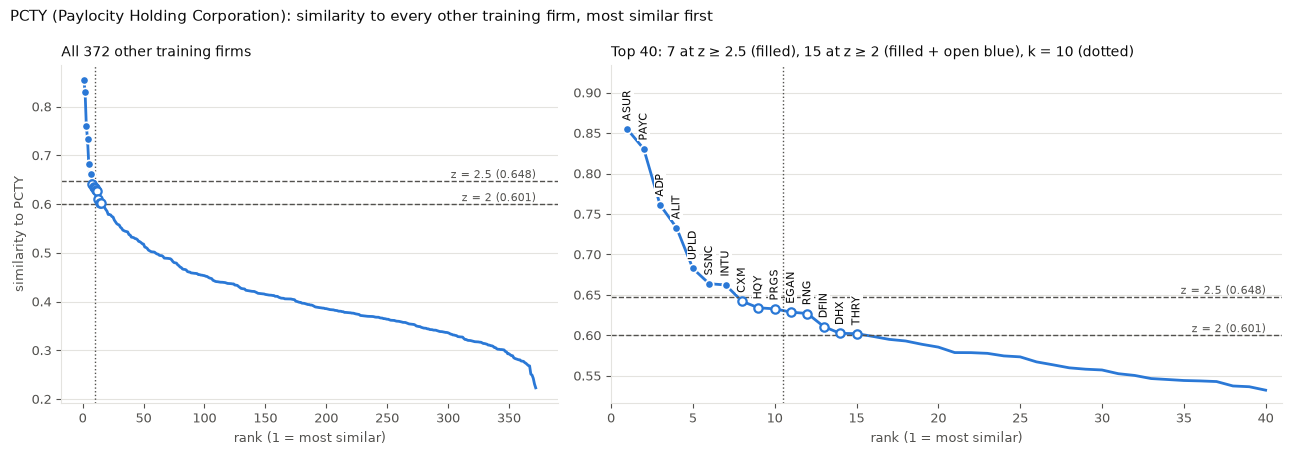

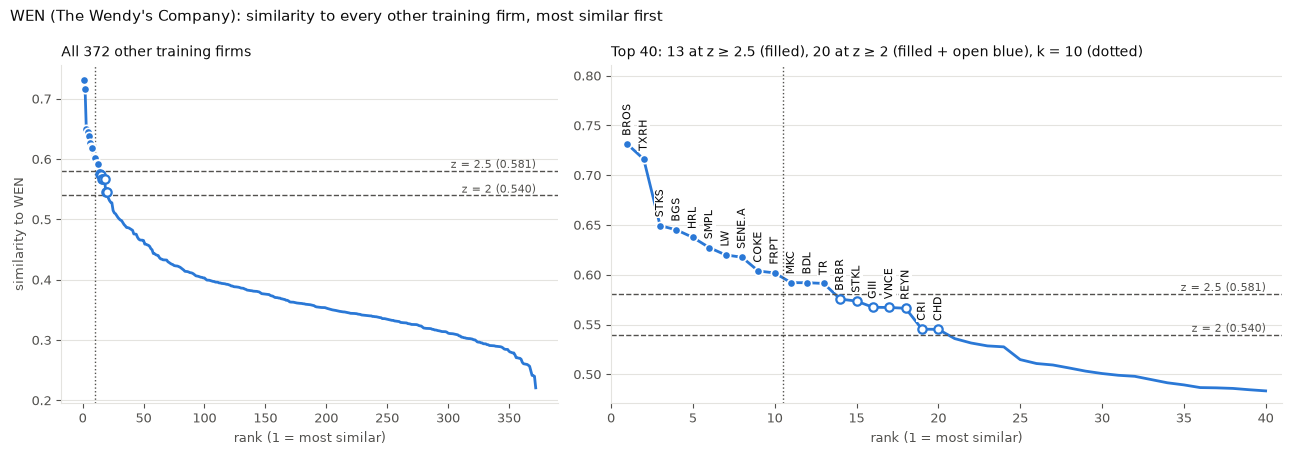

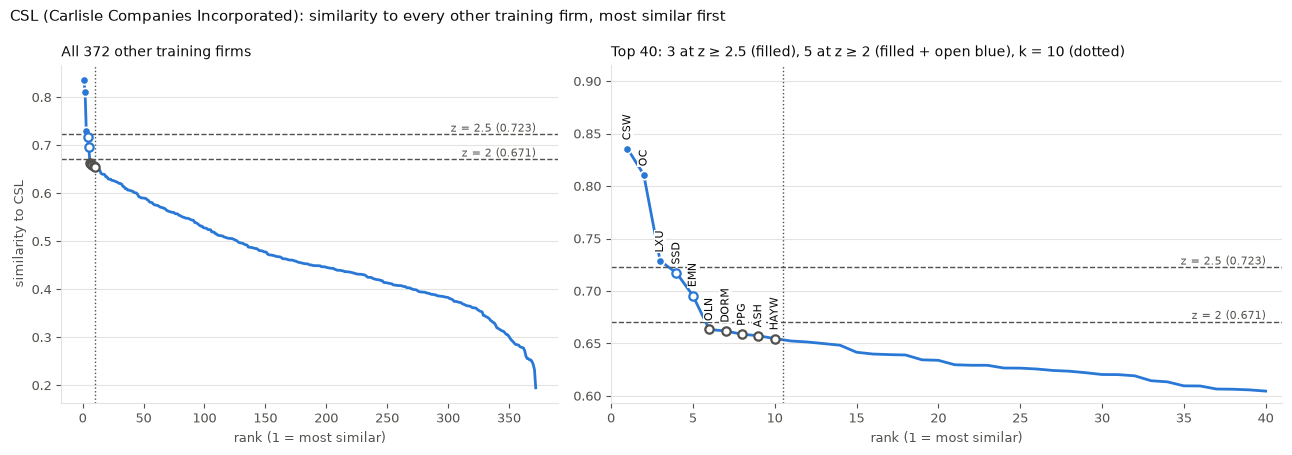

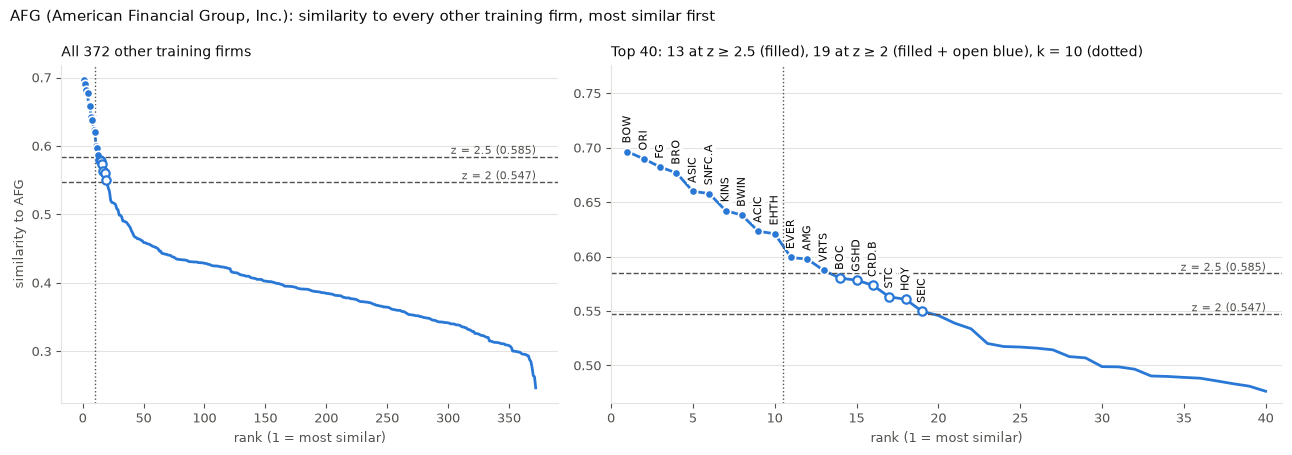

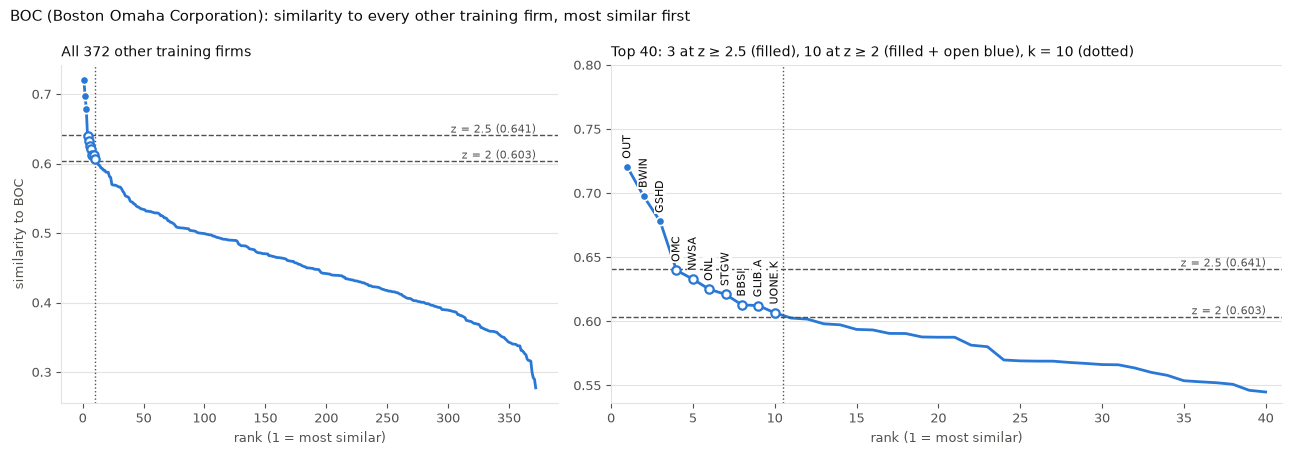

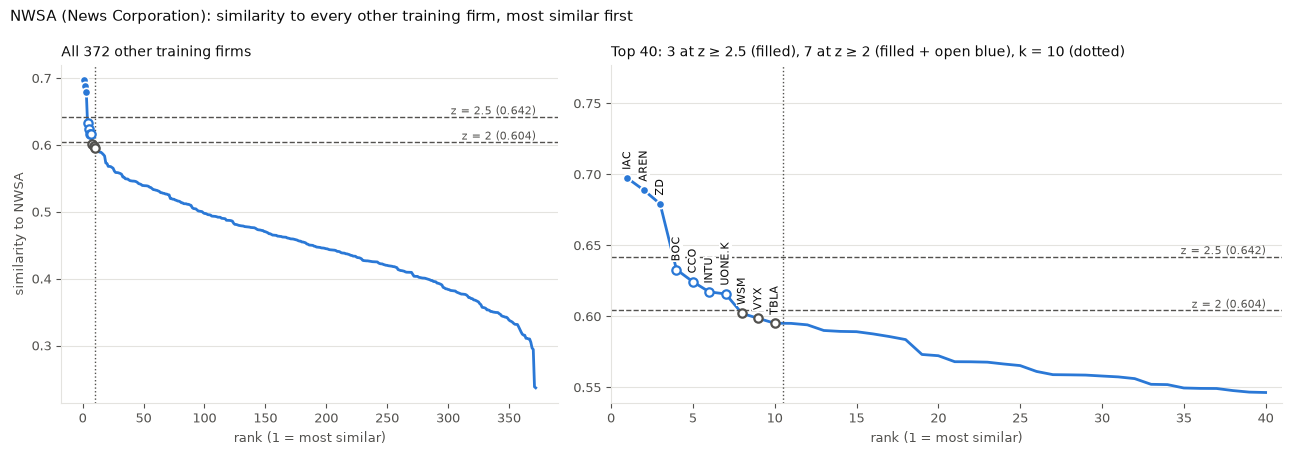

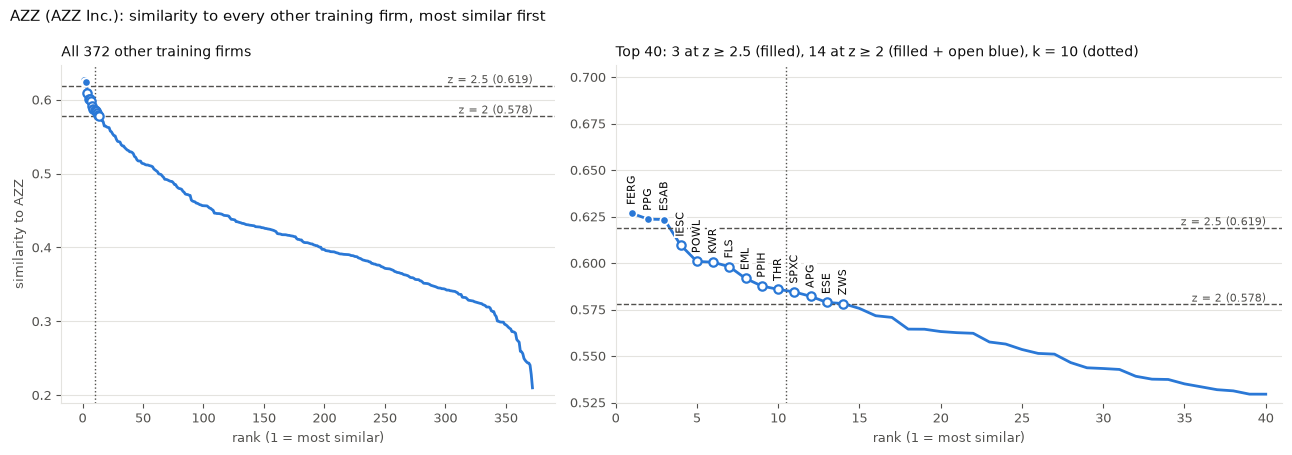

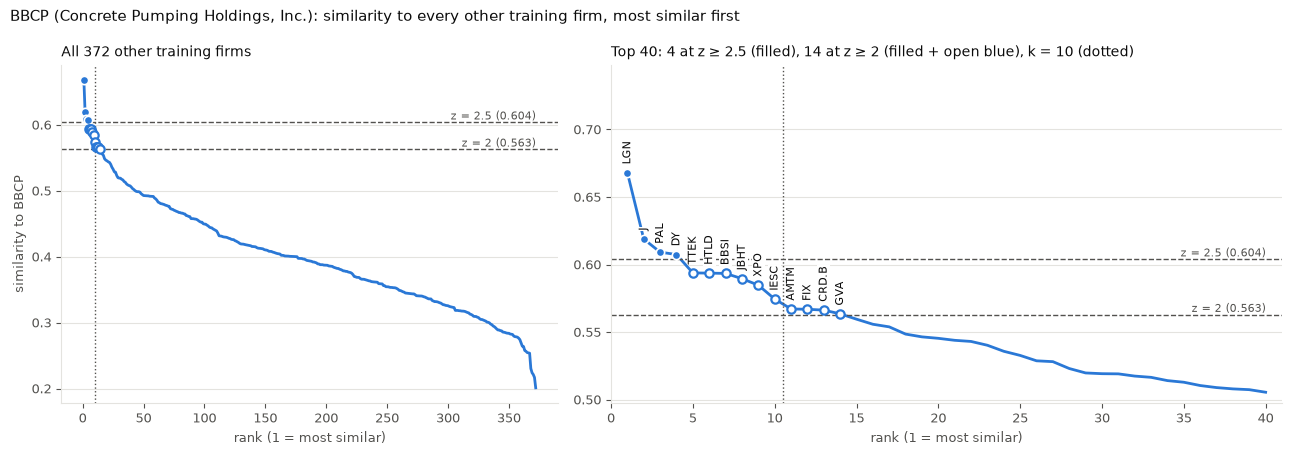

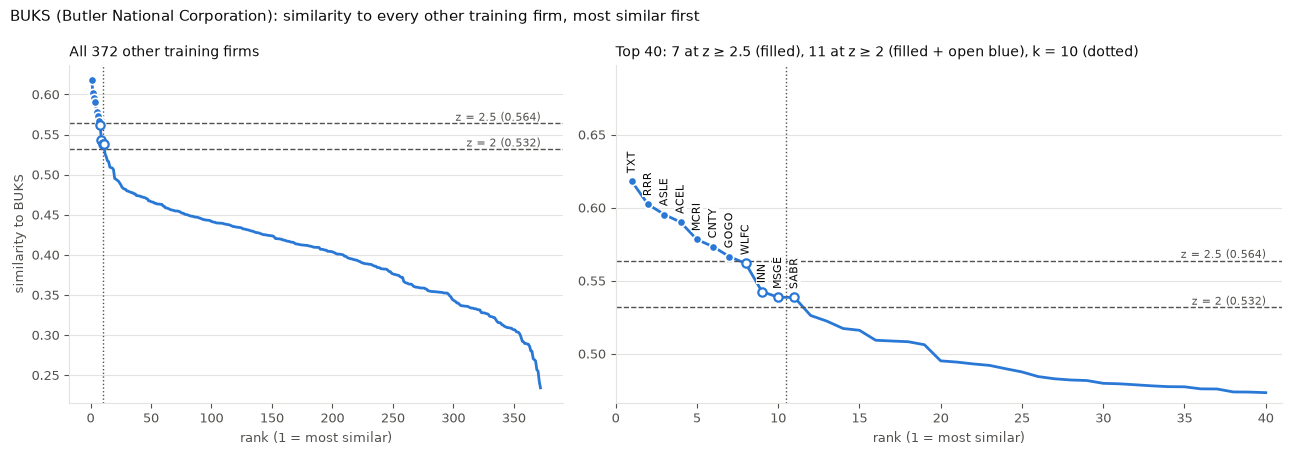

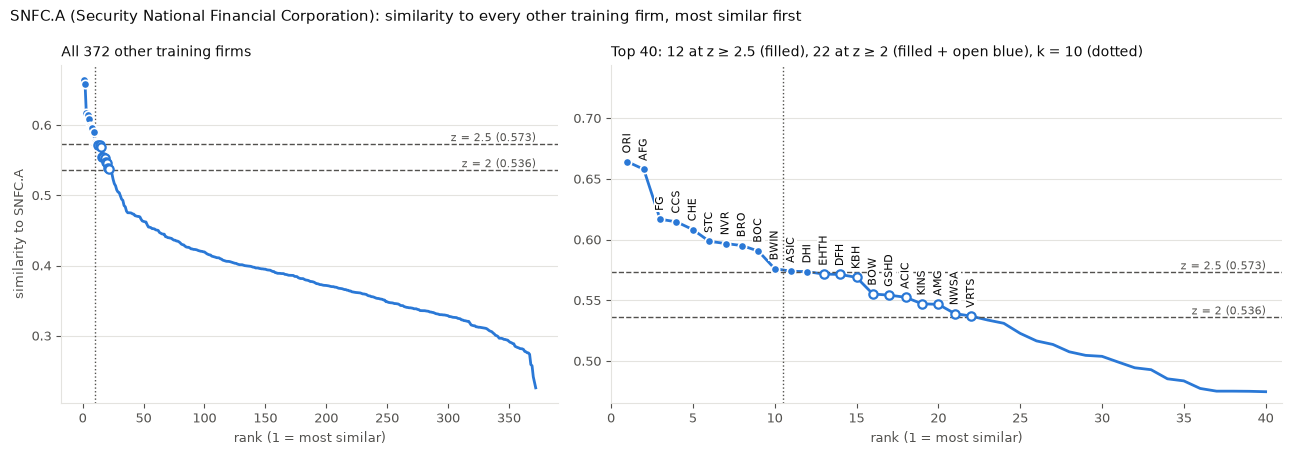

In [9]:
import matplotlib.pyplot as plt

BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
ZOOM = 40
z_lo, z_hi = min(cd.Z_LEVELS), max(cd.Z_LEVELS)

def falloff(t):
    """Similarity of target t to every pool firm by rank (left) and the top ZOOM with candidates labeled (right)."""
    r = ranking[ranking["target"] == id_of[t]].assign(ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    cuts = {lvl: r["similarity"].mean() + lvl * r["similarity"].std(ddof=0) for lvl in cd.Z_LEVELS}   # z = lvl
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
    for ax, n in zip(axes, [len(r), ZOOM]):
        v = r.head(n)
        ax.plot(v["rank"], v["similarity"], color=BLUE, lw=2)
        marks = [(v[v["z"] >= z_hi], BLUE, BLUE), (v[(v["z"] >= z_lo) & (v["z"] < z_hi)], SURFACE, BLUE),
                 (v[v["in_top_k"] & (v["z"] < z_lo)], SURFACE, MUTED)]
        for m, face, edge in marks:
            ax.scatter(m["rank"], m["similarity"], s=36, color=face, edgecolor=SURFACE if face == BLUE else edge,
                       linewidth=1.2 if face == BLUE else 1.6, zorder=3)
        for lvl, cut in cuts.items():
            ax.axhline(cut, color=MUTED, lw=1, ls="--")
            ax.text(n, cut, f"z = {lvl:g} ({cut:.3f})", ha="right", va="bottom", color=MUTED, fontsize=8)
        ax.axvline(cd.TOP_K + 0.5, color=MUTED, lw=1, ls=":")
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_color(GRID)
        ax.tick_params(colors=MUTED, labelsize=9)
        ax.set_xlabel("rank (1 = most similar)", color=MUTED, fontsize=9)
    axes[0].set_ylabel(f"similarity to {t}", color=MUTED, fontsize=9)
    axes[0].set_title(f"All {len(r)} other training firms", loc="left", color=INK, fontsize=10)
    axes[1].set_title(f"Top {ZOOM}: {(r['z'] >= z_hi).sum()} at z ≥ {z_hi:g} (filled), "
                      f"{(r['z'] >= z_lo).sum()} at z ≥ {z_lo:g} (filled + open blue), k = {cd.TOP_K} (dotted)",
                      loc="left", color=INK, fontsize=10)
    axes[1].set_xlim(0, ZOOM + 1)
    axes[1].set_ylim(top=r["similarity"].max() + 0.08)
    for _, c in r[(r["in_top_k"] | (r["z"] >= z_lo)) & (r["rank"] <= ZOOM)].iterrows():
        axes[1].annotate(c["ticker"], (c["rank"], c["similarity"]), xytext=(0, 6), textcoords="offset points",
                         rotation=90, ha="center", va="bottom", fontsize=8, color=INK,
                         bbox=dict(fc=SURFACE, ec="none", pad=0.6))
    fig.suptitle(f"{t} ({info.loc[id_of[t], 'target_company_name']}): similarity to every other training firm, "
                 "most similar first", x=0.01, ha="left", color=INK, fontsize=11)
    fig.tight_layout()
    return fig

for t in SHOWCASE:
    fig = falloff(t)
    fig.savefig(CAND_OUT / f"similarity_falloff_{t}.png", dpi=150)
    plt.show()

**Results, step 4 (SIC2 split).**
- **Candidates per target:** median 13 at z ≥ 2 (range 5-25, none with fewer than 3); median 6 at z ≥ 2.5 (41 targets with fewer than 3).
- **The facets pick up the industry:** 46% of top-10 candidates share the target's 2-digit SIC code, against 7% for random pairs.
- **z ≥ 2 candidates per showcase target:** PCTY 15, WEN 20, CSL 5, AFG 19, BOC 10, NWSA 7, AZZ 14, BBCP 14, BUKS 11, SNFC.A 22. The long lists (SNFC.A, WEN, AFG) are mixed, and the LLM in section 3 sorts them; the short ones (CSL, NWSA) are targets with few close firms in the pool.

## 3. The model: an LLM decides which comps are good (recipe step 6)

**Decided 2026-10-25:** Claude Haiku 5.5 marks every z ≥ 2 candidate of every training target **good (1) or bad (0)**, with a reason of one short sentence (`v0/judge_comps.py`, run outside the notebook, like the facet fill).

- **One call per target.** The model reads the target's name, website and twelve facets, then each candidate's, labeled C1, C2, ... in alphabetical order. It sees no similarity, rank, ticker or multiple, so the order says nothing about how close a candidate is.
- **Good** means in the same business as the target (the same main products or services, sold to the same kind of customers, earning money the same way), so its multiple says something about the target's. **Bad** means a different business, even with a shared industry label, customers or technology. Scale matters less than being in the same business.
- **Code checks** that every candidate is answered once, and maps the labels back to companies. Every prompt and raw answer is kept under `outputs-local/comps_pilot_targets/judge/runs/`; `tables/judgments.csv` has one row per target-comp pair (score, reason, step 4 rank, similarity and z). The evals notebook will sample its pairs from this table.
- **Training, then holdout:** the prompt (and later any weights fit on these pairs) is changed only by looking at training targets. When it is frozen, the same step runs once on the holdout targets.

It is run with `python v0/judge_comps.py --candidates outputs-local/comps_pilot_targets/candidates/<run> --out outputs-local/comps_pilot_targets/judge --workers 4` after section 2 has written a candidates run (the default `--candidates` is the latest run in `comps/`, which belongs to the earlier version). A rerun skips targets already judged with the same prompt and model; a changed split changes the candidate lists, so most targets are judged again.

In [10]:
import judge_comps as jc

JUDGE_TABLE = jc.output_paths(WRITE_OUT / "judge").tables / "judgments.csv"   # judged on this split's candidates (run by judge_comps.py --out)
judgments = (pd.read_csv(JUDGE_TABLE, dtype={"target": str, "comp": str}) if JUDGE_TABLE.exists()
             else pd.DataFrame(columns=["target", "comp", "score", "reason", "prompt_version"]))
judgments = judgments[judgments["prompt_version"] == jc.PROMPT_VERSION]
z2 = ranking[ranking[f"z_ge_{jc.DEFAULT_Z:g}"]][["target", "comp", "rank", "similarity", "z"]]
judged = z2.merge(judgments[["target", "comp", "score", "reason"]], on=["target", "comp"], how="left")
complete = judged.groupby("target")["score"].apply(lambda s: s.notna().all())
judged = judged[judged["target"].isin(complete[complete].index)]
kept = judged.groupby("target")["score"].sum()
print(f"prompt {jc.PROMPT_VERSION}: {complete.sum()} of {len(complete)} training targets judged, {len(judged)} pairs; "
      f"{int(judged['score'].sum())} good ({judged['score'].mean():.0%})")
print(f"good comps per target: median {kept.median():.0f}, range {kept.min():.0f}-{kept.max():.0f}; "
      f"{(kept == 0).sum()} targets with none")
# does the LLM agree with the cosine ranking? share marked good by step 4 rank
bands = pd.cut(judged["rank"], [0, 1, 3, 5, 10, 1000], labels=["1", "2-3", "4-5", "6-10", "11+"])
judged.groupby(bands, observed=True)["score"].agg(pairs="size", good="mean").round(2)

prompt 2026-10-25a: 373 of 373 training targets judged, 4996 pairs; 592 good (12%)
good comps per target: median 1, range 0-8; 109 targets with none


,pairs,good
rank,,
1,373,0.55
2-3,746,0.27
4-5,746,0.12
6-10,1751,0.05
11+,1380,0.01


The showcase targets: every z ≥ 2 candidate in step 4 order, with the LLM's answer (1 good, 0 bad) and reason.

In [11]:
pd.set_option("display.max_colwidth", 120)
for t in SHOWCASE:
    rows = judged[judged["target"] == id_of[t]].assign(comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    print(f"{t} ({info.loc[id_of[t], 'target_company_name']}): {int(rows['score'].sum())} good of {len(rows)}")
    display(rows[["rank", "comp_ticker", "similarity", "z", "score", "reason"]].set_index("rank")
            .round({"similarity": 3, "z": 2}).astype({"score": int}))

PCTY (Paylocity Holding Corporation): 4 good of 15


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,ASUR,0.855,4.68,1,"Cloud payroll, HR and tax filing software and services sold to small and mid-sized employers, closely matching the t..."
2,PAYC,0.830,4.43,1,"Cloud HCM software covering payroll, HR and talent, with payroll processing and tax filing for US employers."
3,ADP,0.761,3.69,1,"Cloud payroll, HR and talent software with payroll processing and tax filing for employers, the closest business match."
4,ALIT,0.733,3.40,1,"Cloud HR and payroll software plus payroll processing for employers, though it leans toward large-employer benefits ..."
5,UPLD,0.683,2.87,0,"Enterprise work management, content and records software, not HR or payroll software."
6,SSNC,0.664,2.67,0,"Investment management, fund administration and back-office software for financial firms, a different business."
7,INTU,0.662,2.65,0,"Consumer and small business financial software, mainly tax preparation and accounting, with payroll as one minor line."
8,CXM,0.642,2.44,0,"Enterprise customer experience and social media management software, not HR or payroll."
9,HQY,0.634,2.35,0,"Health savings account custody and administration, a financial and benefits-account business rather than payroll sof..."


WEN (The Wendy's Company): 4 good of 20


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,BROS,0.731,4.33,1,Drive-thru quick-service restaurant operator with company-owned and franchised shops selling to individual consumers.
2,TXRH,0.716,4.15,1,"Company-owned and franchised casual dining restaurant chain serving consumers with burgers and other menu items, ear..."
3,STKS,0.649,3.33,1,"Restaurant operator and brand licensor serving diners, though upscale steakhouse and Japanese formats differ from qu..."
4,BGS,0.645,3.28,0,"Shelf-stable and frozen packaged foods sold through grocery channels, not prepared food sold from restaurants."
5,HRL,0.638,3.19,0,"Meat processor selling packaged foods to grocers and foodservice distributors, not a restaurant operator."
6,SMPL,0.627,3.06,0,"Branded protein snacks and shakes sold through retail stores, made by contract manufacturers, not restaurant food se..."
7,LW,0.620,2.97,0,Frozen potato manufacturer supplying restaurants and grocers; a food supplier rather than a restaurant operator.
8,SENE.A,0.618,2.95,0,"Canned and frozen vegetable processor selling to grocers and distributors, not a restaurant business."
9,COKE,0.604,2.78,0,"Beverage bottler and distributor selling to retailers and outlets, not a restaurant operator."


CSL (Carlisle Companies Incorporated): 2 good of 5


...

,comp_ticker,similarity,z,score,reason
rank,,,,,
1,LGN,0.668,3.28,0,"Building mechanical, electrical and plumbing services; not concrete pumping or placement."
2,J,0.619,2.68,0,"Engineering, consulting and government operations services; no equipment-based concrete placement work."
3,PAL,0.609,2.56,0,Finished-vehicle transportation for automakers and dealers; a different logistics service entirely.
4,DY,0.607,2.54,0,Telecommunications network construction and maintenance; no concrete pumping services.
5,TTEK,0.594,2.38,0,"Water, environmental and infrastructure consulting and engineering; no concrete pumping operations."
6,HTLD,0.594,2.37,0,Truckload freight hauling for shippers; moves goods rather than pumping concrete at job sites.
7,BBSI,0.593,2.37,0,"Outsourced HR, payroll and workers' compensation insurance; unrelated to on-site concrete pumping."
8,JBHT,0.590,2.32,0,Intermodal and truckload freight transportation and brokerage; a different logistics business.
9,XPO,0.585,2.26,0,Less-than-truckload freight transportation through service centers; unrelated to concrete pumping.


BUKS (Butler National Corporation): 3 good of 11


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,TXT,0.618,3.34,0,"Primarily manufactures business jets, military helicopters and defense vehicles, a diversified OEM business unlike a..."
2,RRR,0.602,3.10,1,"Operates Las Vegas casino gaming resorts for local and visitor gamblers, matching the target's casino gaming operati..."
3,ASLE,0.595,2.99,0,"Trades and leases used aircraft and engines to airlines and lessors, a different business from business-jet modifica..."
4,ACEL,0.590,2.91,0,"Operates tavern and truck-stop gaming terminal routes with revenue sharing, unlike casino management or aircraft mod..."
5,MCRI,0.578,2.73,1,"Operates casino gaming floors for leisure gamblers, matching the target's casino gaming operations, though it owns i..."
6,CNTY,0.573,2.65,1,"Owns and operates casino gaming floors serving patrons, overlapping the target's Kansas casino gaming operations, th..."
7,GOGO,0.567,2.54,0,"Sells in-flight internet connectivity and service plans, a telecom-style business that differs from aircraft modific..."
8,WLFC,0.562,2.47,0,"Leases aircraft engines and provides engine repair to airlines, differing from business-aircraft modification and in..."
9,INN,0.543,2.17,0,"Owns and leases select-service hotels to travelers, a lodging business with no gaming or aircraft modification overlap."


SNFC.A (Security National Financial Corporation): 1 good of 22


,comp_ticker,similarity,z,score,reason
rank,,,,,
1,ORI,0.664,3.72,0,"Title, mortgage guaranty and general insurer; mortgage-related insurance differs from life underwriting, mortgage or..."
2,AFG,0.658,3.64,0,Mainly specialty commercial property and casualty insurer; annuities are secondary and there is no mortgage or cemet...
3,FG,0.617,3.09,1,"Sells life insurance and annuities to individuals through agents and banks, underwriting policies much like the targ..."
4,CCS,0.615,3.06,0,"Homebuilder with ancillary mortgage and title services; primary business is building and selling homes, not insuranc..."
5,CHE,0.608,2.97,0,"Hospice healthcare and plumbing services; no life insurance, mortgage lending or cemetery and mortuary business."
6,STC,0.599,2.84,0,"Title insurance, escrow and real estate data provider; transaction-based real estate services rather than life insur..."
7,NVR,0.597,2.82,0,"Homebuilder with mortgage, title and insurance brokerage for buyers; homebuilding is the core business, not life ins..."
8,BRO,0.595,2.79,0,Insurance brokerage earning commissions on commercial and personal lines; it does not underwrite life policies or or...
9,BOC,0.591,2.73,0,"Billboard advertising, broadband and insurance agency mix; no life underwriting, mortgage lending or death care."


**Results, step 6 (prompt 2026-10-25a, this split; 3.25M input and 0.50M output tokens).**
- **373 targets, 4,996 pairs; 592 marked good (12%).** Median 1 good comp per target; 109 targets with none.
- **It mostly agrees with the cosine order:** 55% of rank-1 candidates are good, 27% at ranks 2-3, 12% at 4-5, 5% at 6-10, 1% past 10.
- **It separates business models that cosine mixes:** PCTY keeps ASUR, PAYC, ADP and ALIT; WEN keeps the restaurants and franchisors (BROS, TXRH, STKS, BDL); AFG keeps the insurers (BOW, ORI, FG, ASIC, KINS); BUKS keeps RRR, MCRI and CNTY.
- **It is strict:** AZZ and BBCP get no good comp, NWSA only AREN, and SNFC.A only FG.

## 4. Comps without embeddings

Two ways to find comps that skip the embedding shortlist of section 2, to see whether it helps or hurts:

- **The LLM suggests comps directly** (`v0/suggest_comps.py`, Claude Haiku 5.5, prompt 2026-10-25a). Every call holds the whole training pool: all 373 firms, labeled P001, ... in alphabetical order, each with its name, website and the facets that say what business it is in (core offering, products, services, customers, revenue model). The pool is the same for every target, so it is cached (about 99k tokens; a call after the first pays a tenth for it). Then comes the target, with all twelve facets. The model picks **at most ten companies in the same business, best first**, each with a reason; code drops the target itself, unknown labels and repeats. It is run with `python v0/suggest_comps.py --candidates outputs-local/comps_pilot_targets/candidates/<run> --out outputs-local/comps_pilot_targets/suggest --workers 4` (the pool is the training firms of that candidates run's split).
- **Same SIC code**, no model at all: every other training firm with the target's 4-, 3- or 2-digit SIC code (from the company list).

Both are scored in section 6 with equal weights (there is no similarity to weight by).

In [12]:
import suggest_comps as sg

SUGGEST_TABLE = sg.output_paths(WRITE_OUT / "suggest").tables / "suggestions.csv"   # asked on this split (suggest_comps.py --out)
suggestions = (pd.read_csv(SUGGEST_TABLE, dtype={"target": str, "comp": str}) if SUGGEST_TABLE.exists()
               else pd.DataFrame(columns=["target", "rank", "comp", "reason", "prompt_version"]))
suggestions = suggestions[suggestions["prompt_version"] == sg.PROMPT_VERSION]
# suggestions/ also holds files for targets asked under an earlier split (now holdout, never re-asked): keep this split's training pool only
pool = set(training)
in_pool = suggestions["target"].isin(pool) & (suggestions["comp"].isna() | suggestions["comp"].isin(pool))
print(f"suggestions table: {len(suggestions)} rows, {int((~in_pool).sum())} left out (target or pick not in this split's training pool)")
suggestions = suggestions[in_pool]
direct = suggestions.dropna(subset=["comp"])[["target", "rank", "comp", "reason"]]
asked = sorted(set(suggestions["target"]))
n_direct = direct.groupby("target").size().reindex(asked, fill_value=0)
print(f"LLM direct, prompt {sg.PROMPT_VERSION}: {len(asked)} of {len(training)} training targets asked, "
      f"{len(direct)} comps; median {n_direct.median():.0f} per target, {(n_direct == 0).sum()} targets with none")

# where the LLM's own picks sit in the cosine ranking, and what the step 6 judge said about them
where = (direct.merge(ranking[["target", "comp", "rank", "z"]].rename(columns={"rank": "cosine_rank"}),
                      on=["target", "comp"], how="left")
         .merge(judged[["target", "comp", "score"]].rename(columns={"score": "judge_good"}),
                on=["target", "comp"], how="left"))
print(f"of the LLM's direct picks: {(where['z'] >= 2).mean():.0%} are cosine candidates at z >= 2, "
      f"median cosine rank {where['cosine_rank'].median():.0f}, {(where['cosine_rank'] > 20).mean():.0%} past rank 20; "
      f"{where['judge_good'].eq(1).mean():.0%} were also marked good in step 6")

# same-SIC peers: every other training firm sharing the code
tr = info.loc[training].reset_index()
sic_pairs = {}
for level, col in [("SIC4", "target_sic4_code"), ("SIC3", "target_sic3_code"), ("SIC2", "target_sic2_code")]:
    m = tr[["IQ_COMPANY_ID", col]].merge(tr[["IQ_COMPANY_ID", col]], on=col, suffixes=("_t", "_c"))
    m = m[m["IQ_COMPANY_ID_t"] != m["IQ_COMPANY_ID_c"]]
    sic_pairs[level] = m.rename(columns={"IQ_COMPANY_ID_t": "target", "IQ_COMPANY_ID_c": "comp"})[["target", "comp"]]
    n = sic_pairs[level].groupby("target").size().reindex(training, fill_value=0)
    print(f"same {level}: median {n.median():.0f} peers per target, {(n == 0).sum()} targets with none")

suggestions table: 1137 rows, 0 left out (target or pick not in this split's training pool)
LLM direct, prompt 2026-10-25a: 373 of 373 training targets asked, 1107 comps; median 3 per target, 30 targets with none
of the LLM's direct picks: 86% are cosine candidates at z >= 2, median cosine rank 3, 9% past rank 20; 51% were also marked good in step 6
same SIC4: median 2 peers per target, 86 targets with none
same SIC3: median 5 peers per target, 41 targets with none
same SIC2: median 10 peers per target, 6 targets with none


The showcase targets: the LLM's direct picks, best first, with where each sits in the cosine ranking (section 2) and whether step 6 marked it good (blank: not a z ≥ 2 candidate, so step 6 never saw it).

In [13]:
show = where[where["target"].isin([id_of[t] for t in SHOWCASE])].assign(
    target_ticker=lambda d: d["target"].map(info["target_ciq_ticker"]),
    comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
for t in SHOWCASE:
    rows = show[show["target_ticker"] == t]
    print(f"{t}: {len(rows)} picks")
    if len(rows):
        display(rows[["rank", "comp_ticker", "cosine_rank", "z", "judge_good", "reason"]].set_index("rank")
                .round({"z": 2}))

PCTY: 5 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,PAYC,2,4.43,1.0,"Sells cloud HCM software covering payroll, HR, time and talent to US employers, sold as a per-employee SaaS platform."
2.0,ADP,3,3.69,1.0,"Provides cloud payroll, HR, benefits and talent software plus payroll processing and tax filing, earning per-employe..."
3.0,ASUR,1,4.68,1.0,"Sells subscription cloud HCM software for payroll, HR, time and tax filing to small and mid-sized employers."
4.0,BBSI,17,1.94,NaN,"Delivers outsourced payroll, HR and benefits administration to small and mid-sized employers, priced per employee."
5.0,ALIT,4,3.40,1.0,"Provides cloud HR and payroll software plus outsourced payroll and benefits administration to employers, though aime..."


WEN: 3 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,BROS,1,4.33,1.0,Operates and franchises drive-thru quick-service restaurants selling made-to-order drinks and food to individual con...
2.0,TXRH,2,4.15,1.0,"Company-operated and franchised casual restaurant chain selling prepared food and beverages to consumers, sharing We..."
3.0,BDL,12,2.63,1.0,"Operates restaurants and earns franchise fees and royalties from franchised restaurants, so the restaurant-operator ..."


CSL: 3 picks


...

,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,CDNL,22,1.76,NaN,"Self-performs on-site civil work with its own crews and equipment for developers and municipalities, billed per proj..."
2.0,NPKI,118,0.37,NaN,"Rents equipment and sells site-access services on construction projects, a partial overlap through its fleet-based, ..."


BUKS: 5 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,ISSC,15,1.76,NaN,"Avionics retrofit and forward-fit upgrades for business and commercial aircraft, with certification support, matchin..."
2.0,ASLE,3,2.99,0.0,"Aircraft component repair, overhaul and teardown services for airlines and operators, similar to Butler's aircraft m..."
3.0,MCRI,5,2.73,1.0,"Operates casino gaming properties serving local and visiting patrons, the same gaming operations Butler runs in Kansas."
4.0,CNTY,6,2.65,1.0,"Owns and operates casinos with gaming floors, hotels and restaurants, matching the gaming and hospitality business B..."
5.0,RRR,2,3.10,1.0,"Operates casino resorts for local residents and visitors, with gaming, hotel and food services similar to Butler's c..."


SNFC.A: 1 picks


,comp_ticker,cosine_rank,z,judge_good,reason
rank,,,,,
1.0,FG,3,3.09,1.0,"Sells individual life insurance and retirement annuities through agents, earning premiums and investment income on p..."


**Results, comps without embeddings (prompt 2026-10-25a, this split; 36.6M input tokens, 36.0M of them cached, and 0.29M output).**
- **LLM direct:** 1,107 picks, median 3 per target; 30 targets with none.
- **The embedding shortlist rarely hides a comp the LLM would choose:** 86% of the direct picks are cosine candidates at z ≥ 2 anyway (median cosine rank 3; 9% past rank 20).
- **The two original LLM selection rules agree on about half (LLM→cosine retains the direct picks):** 51% of the direct picks were also marked good in step 6.
- **Same SIC:** SIC4 gives a median of 2 peers (86 targets with none), SIC3 5 (41 with none), SIC2 10 (6 with none).

## 5. LLM then cosine

The LLM's direct selections from section 4 are fixed first. Cosine scores from the full section 2 ranking then reorder those selected peers (`v0/llm_then_cosine.py`); section 6 uses the same scores as valuation weights. There is no z-score cutoff and no new model call. Because the LLM chose at most ten peers and this method keeps up to ten, it changes neither the peer set nor target coverage.

The `reason` for each pair comes from the saved direct LLM answer in `suggestions.csv`. It explains the LLM's original choice; cosine does not generate reasons.


In [14]:
import llm_then_cosine as lc

reverse = lc.rank_selected(direct, ranking, max_peers=sg.MAX_COMPS)
assert len(reverse) == len(direct)
changed = int(reverse["rank"].ne(reverse["llm_rank"]).sum())
print(f"{len(reverse)} peers for {reverse['target'].nunique()} of {len(training)} training targets; "
      f"{changed} positions changed; no peer for {len(training) - reverse['target'].nunique()} targets")

HYBRID_OUT = WRITE_OUT / "llm_then_cosine" / RUN
HYBRID_OUT.mkdir(parents=True, exist_ok=True)
reverse.to_csv(HYBRID_OUT / "pairs.csv", index=False)


1107 peers for 343 of 373 training targets; 580 positions changed; no peer for 30 targets


The showcase targets: the new rank among the LLM-selected peers, the LLM's original rank, the peer's rank against the full cosine pool, and the original LLM reason.


In [15]:
for t in SHOWCASE:
    rows = reverse[reverse["target"] == id_of[t]].assign(
        comp_ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    print(f"{t}: {len(rows)} selected peers")
    if len(rows):
        display(rows[["rank", "llm_rank", "comp_ticker", "cosine_rank", "similarity", "z", "reason"]]
                .set_index("rank").round({"similarity": 3, "z": 2}))


PCTY: 5 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,3.0,ASUR,1,0.855,4.68,"Sells subscription cloud HCM software for payroll, HR, time and tax filing to small and mid-sized employers."
2,1.0,PAYC,2,0.830,4.43,"Sells cloud HCM software covering payroll, HR, time and talent to US employers, sold as a per-employee SaaS platform."
3,2.0,ADP,3,0.761,3.69,"Provides cloud payroll, HR, benefits and talent software plus payroll processing and tax filing, earning per-employe..."
4,5.0,ALIT,4,0.733,3.40,"Provides cloud HR and payroll software plus outsourced payroll and benefits administration to employers, though aime..."
5,4.0,BBSI,17,0.595,1.94,"Delivers outsourced payroll, HR and benefits administration to small and mid-sized employers, priced per employee."


WEN: 3 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,1.0,BROS,1,0.731,4.33,Operates and franchises drive-thru quick-service restaurants selling made-to-order drinks and food to individual con...
2,2.0,TXRH,2,0.716,4.15,"Company-operated and franchised casual restaurant chain selling prepared food and beverages to consumers, sharing We..."
3,3.0,BDL,12,0.592,2.63,"Operates restaurants and earns franchise fees and royalties from franchised restaurants, so the restaurant-operator ..."


CSL: 3 selected peers


...

,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,1.0,CDNL,22,0.543,1.76,"Self-performs on-site civil work with its own crews and equipment for developers and municipalities, billed per proj..."
2,2.0,NPKI,118,0.429,0.37,"Rents equipment and sells site-access services on construction projects, a partial overlap through its fleet-based, ..."


BUKS: 5 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,5.0,RRR,2,0.602,3.10,"Operates casino resorts for local residents and visitors, with gaming, hotel and food services similar to Butler's c..."
2,2.0,ASLE,3,0.595,2.99,"Aircraft component repair, overhaul and teardown services for airlines and operators, similar to Butler's aircraft m..."
3,3.0,MCRI,5,0.578,2.73,"Operates casino gaming properties serving local and visiting patrons, the same gaming operations Butler runs in Kansas."
4,4.0,CNTY,6,0.573,2.65,"Owns and operates casinos with gaming floors, hotels and restaurants, matching the gaming and hospitality business B..."
5,1.0,ISSC,15,0.516,1.76,"Avionics retrofit and forward-fit upgrades for business and commercial aircraft, with certification support, matchin..."


SNFC.A: 1 selected peers


,llm_rank,comp_ticker,cosine_rank,similarity,z,reason
rank,,,,,,
1,1.0,FG,3,0.617,3.09,"Sells individual life insurance and retirement annuities through agents, earning premiums and investment income on p..."


**Results, LLM then cosine (this split).** The method retains all 1,107 direct LLM picks for 343 of 373 training targets; 30 targets still have no peer. Cosine changes 580 within-target rank positions. The reasons are unchanged LLM responses, not new evidence. Valuation results follow in section 6.

## 6. Step 7: estimates against the actual multiples

**The ground truth** is each target's actual EV/EBITDA, from the financials table. This is the first place the multiples are read (`v0/valuation.py`).

**The estimate (step 7)** is a weighted average of the comps' EV/EBITDA; the median is shown too, for comparison with pre-v0. The comp rules compared:
- **No matching:** the median multiple of all the other training firms. Any comp rule has to beat it. In pre-v0 every matching method came out at about 35% median absolute error, the same as no matching (34.6%).
- **Cosine only (no LLM):** the step 4 candidates (top 10, z ≥ 2 or z ≥ 2.5), weighted by their similarity.
- **Cosine then LLM (LLM good comps):** the z ≥ 2 candidates the LLM marked good (section 3), weighted by their similarity. The like-for-like comparison is with **cosine z ≥ 2**: the same candidates, without the LLM's choice.
- **Without embeddings** (section 4): the LLM's direct picks, and same-SIC peers, with equal weights.
- **LLM then cosine** (section 5): the direct LLM picks, weighted by cosine similarity.

**Which targets each row scores:** every rule runs on all 373 training targets. A rule that finds no comp for a target gives it no estimate (the `targets` column counts the rest): the LLM marks no candidate good for some targets, and finds no same-business comp for others (AZZ and BBCP here). So the second table scores every rule on the same targets, those where **both original LLM selection rules and LLM→cosine** give an estimate, and its rows can be compared directly.

**Measures:** median absolute % error, % of targets within 25%, Spearman (estimate, actual), and % of targets closer than with no matching. They are computed here for the **training targets** (development). The holdout is scored once, at the end.

In [16]:
ev = financials["target_ev_to_ebitda"]          # the answer key: first read here
actual = ev[training]
NO_MATCH = "no matching (median of the other training firms)"
results = {NO_MATCH: vl.no_matching(training, training, ev)}
for name, pairs in {"top 10": ranking[ranking["in_top_k"]],
                    **{f"z ≥ {lvl:g}": ranking[ranking[f"z_ge_{lvl:g}"]] for lvl in cd.Z_LEVELS}}.items():
    results[f"cosine {name}, similarity-weighted mean"] = vl.estimate(pairs, ev, weight="similarity")
    results[f"cosine {name}, median"] = vl.estimate(pairs, ev, how="median")
LLM_RULE = "LLM good comps (from z ≥ 2), similarity-weighted mean"
good = judged[judged["score"] == 1]
if len(good):
    results[LLM_RULE] = vl.estimate(good, ev, weight="similarity")
    results["LLM good comps (from z ≥ 2), median"] = vl.estimate(good, ev, how="median")
DIRECT_RULE = "LLM suggests directly (no embeddings), mean"
if len(direct):
    results[DIRECT_RULE] = vl.estimate(direct, ev)
    results["LLM suggests directly (no embeddings), median"] = vl.estimate(direct, ev, how="median")
HYBRID_RULE = "LLM then cosine, similarity-weighted mean"
results[HYBRID_RULE] = vl.estimate(reverse, ev, weight="similarity")
for level, pairs in sic_pairs.items():
    results[f"same {level} (no embeddings, no LLM), mean"] = vl.estimate(pairs, ev)
evaluation = vl.summary(results, actual, baseline=NO_MATCH)
print(f"{len(training)} training targets; comps from the other training firms")
evaluation.round(2)

373 training targets; comps from the other training firms


,targets,comps per target (median),median abs % error,% within 25%,"Spearman(estimate, actual)",% closer than no matching
comp rule,,,,,,
no matching (median of the other training firms),373,372.0,31.92,38.87,NaN,NaN
"cosine top 10, similarity-weighted mean",373,10.0,28.82,42.90,0.35,50.94
"cosine top 10, median",373,10.0,31.01,41.29,0.31,52.28
"cosine z ≥ 2, similarity-weighted mean",373,13.0,29.58,42.63,0.31,49.33
"cosine z ≥ 2, median",373,13.0,31.10,38.34,0.25,51.74
"cosine z ≥ 2.5, similarity-weighted mean",368,6.0,30.23,42.66,0.33,51.36
"cosine z ≥ 2.5, median",368,6.0,32.10,41.30,0.30,51.63
"LLM good comps (from z ≥ 2), similarity-weighted mean",264,2.0,30.50,40.91,0.44,50.00
"LLM good comps (from z ≥ 2), median",264,2.0,30.50,40.53,0.42,50.38


The same rules on the targets where both original LLM selection rules and LLM→cosine give an estimate, so every row is scored on the same companies. (Same-SIC rows can still have fewer, where a target has no same-code peer.)

In [17]:
covered = pd.Index(training)
for rule in (LLM_RULE, DIRECT_RULE, HYBRID_RULE):
    covered = covered.intersection(results[rule].index) if rule in results else pd.Index([])
evaluation_covered = vl.summary({k: v.loc[v.index.intersection(covered)] for k, v in results.items()},
                                actual[covered], baseline=NO_MATCH) if len(covered) else pd.DataFrame()
print(f"{len(covered)} of {len(training)} training targets have an estimate from all three LLM-containing routes")
evaluation_covered.round(2)

264 of 373 training targets have an estimate from all three LLM-containing routes


,targets,comps per target (median),median abs % error,% within 25%,"Spearman(estimate, actual)",% closer than no matching
comp rule,,,,,,
no matching (median of the other training firms),264,372.0,31.64,40.91,NaN,NaN
"cosine top 10, similarity-weighted mean",264,10.0,28.31,44.32,0.38,52.27
"cosine top 10, median",264,10.0,30.44,40.15,0.33,53.41
"cosine z ≥ 2, similarity-weighted mean",264,13.0,28.71,45.08,0.33,48.86
"cosine z ≥ 2, median",264,13.0,30.97,38.64,0.27,52.27
"cosine z ≥ 2.5, similarity-weighted mean",264,6.0,29.47,43.56,0.37,53.79
"cosine z ≥ 2.5, median",264,6.0,32.11,40.15,0.32,53.79
"LLM good comps (from z ≥ 2), similarity-weighted mean",264,2.0,30.50,40.91,0.44,50.00
"LLM good comps (from z ≥ 2), median",264,2.0,30.50,40.53,0.42,50.38


The showcase targets: actual multiple, and each rule's estimate and error (% of actual).

In [18]:
per_target = pd.concat({name: vl.errors(r, actual) for name, r in results.items()},
                       names=["comp rule", "IQ_COMPANY_ID"]).reset_index()
per_target.insert(2, "ticker", per_target["IQ_COMPANY_ID"].map(info["target_ciq_ticker"]))
show = per_target[per_target["ticker"].isin(SHOWCASE)]
SHOW_RULES = [NO_MATCH, "cosine z ≥ 2, similarity-weighted mean", LLM_RULE, DIRECT_RULE, HYBRID_RULE]
wide = show[show["comp rule"].isin(SHOW_RULES)].pivot(index="ticker", columns="comp rule",
                                                       values=["estimate", "error %"])
wide = wide.reindex(SHOWCASE).reindex(columns=SHOW_RULES, level=1)
wide.insert(0, ("actual", ""), actual.rename(index=info["target_ciq_ticker"]).reindex(SHOWCASE))
wide.round(1)

actual                                         estimate                                                                                               \
comp rule        no matching (median of the other training firms) cosine z ≥ 2, similarity-weighted mean LLM good comps (from z ≥ 2), similarity-weighted mean   
ticker                                                                                                                                                           
PCTY        22.1                                             10.6                                   13.5                                                  14.5   
WEN         10.2                                             10.6                                   11.0                                                  14.1   
CSL         12.0                                             10.6                                   10.3                                                  12.5   
AFG          9.3                                             10.6                                   10.6                                                   8.3   
BOC         12.1                                             10.6                                   11.2                                                  16.2   
NWSA        12.7                                             10.6                                   10.1                                                   6.1   
AZZ          6.4                                             10.6                                   14.1                                                   NaN   
BBCP         6.9                                             10.6                                   12.6                                                   NaN   
BUKS         7.3                                             10.6                                    9.7                                                   9.2   
SNFC.A       5.7                                             10.6                                   10.5                                                   5.3   

                                                                                                                                         error %                                         \
comp rule LLM suggests directly (no embeddings), mean LLM then cosine, similarity-weighted mean no matching (median of the other training firms) cosine z ≥ 2, similarity-weighted mean   
ticker                                                                                                                                                                                    
PCTY                                             13.6                                      13.9                                            -52.1                                  -38.8   
WEN                                              16.0                                      16.8                                              3.9                                    7.8   
CSL                                              12.4                                      12.4                                            -11.8                                  -14.2   
AFG                                               8.2                                       8.3                                             14.0                                   14.0   
BOC                                              12.5                                      12.8                                            -12.2                                   -7.2   
NWSA                                              9.1                                       8.9                                            -16.5                                  -20.3   
AZZ                                               8.9                                       8.9                                             66.8                                  121.7   
BBCP                             

**Results, step 7 (training targets, this split).**
- **All 373 targets:** no matching 31.9% median absolute error; cosine 28.8-32.1% (similarity-weighted mean 28.8% at top 10, 29.6% at z ≥ 2); LLM good comps 30.5% (on the 264 it covers); LLM direct 30.6% (343); LLM→cosine 30.6% (the same 343); same SIC 35.1-36.7%.
- **On the 264 targets all three LLM-containing routes cover:** LLM→cosine 27.4% (Spearman 0.44), LLM direct 27.5% (0.43), cosine top 10 28.3% (0.38), cosine z ≥ 2 28.7% (0.33), cosine→LLM good comps 30.5% (0.44), no matching 31.6%, same SIC 32.5-34.1% (0.22-0.25).
- **Every way of choosing comps lands within about 27-33%,** as in pre-v0: embeddings, the LLM, or both in either order; same-SIC peers are worst. The gaps between the better routes are about a point, which is within what changing the split alone moved them (the same cosine rules shifted by 2-4 points between the earlier size-stratified split and this one).
- **The right peers can still miss:** WEN is +38% with its LLM-good comps (BROS, TXRH, STKS, BDL) against +4% with no matching; NWSA is -52% with AREN alone. Where the LLM's comps help: SNFC.A goes from +87% (no matching) to -7% (FG), AFG from +14% to -11%.
- **What this points to:** choosing comps doesn't look like the bottleneck. Next candidates are the estimate rule (weights fit on training pairs, scale, shrinking toward the all-firm median) and a rule for targets with no comp (AZZ and BBCP have no LLM-good comp).

In [19]:
VAL_OUT = WRITE_OUT / "valuation" / RUN
VAL_OUT.mkdir(parents=True, exist_ok=True)
evaluation.to_csv(VAL_OUT / "summary.csv")
evaluation_covered.to_csv(VAL_OUT / "summary_llm_covered.csv")
per_target.to_csv(VAL_OUT / "per_target.csv", index=False)
(VAL_OUT / "run.json").write_text(json.dumps({
    "run": RUN, "candidates_run": CAND_OUT.name, "split_run": SPLIT_OUT.name,
    "targets": "training", "pool": "training (not the target itself)", "rules": list(results),
    "baseline": NO_MATCH, "llm_rule": LLM_RULE, "llm_prompt_version": jc.PROMPT_VERSION,
    "llm_targets_judged": int(complete.sum()), "direct_prompt_version": sg.PROMPT_VERSION,
    "direct_targets_asked": len(asked), "targets_both_llm_rules": len(covered),
}, indent=1, ensure_ascii=False), encoding="utf-8")
print("wrote", VAL_OUT.relative_to(ROOT))

wrote outputs-local\comps_pilot_targets\valuation\20261027T204930Z


## 7. Which facets drive the embedding score (and what company size would add)

The combined similarity is the equal-weight mean of the per-facet cosines over eleven facets; company size (F9) is left out of it. This section asks how much each facet adds, **including F9**, whose text is embedded the same way (same model) so that it can be compared on the same scale. Marked with an asterisk, it does not enter the combined similarity. Three views, all on this split's training pool:

1. **Separation (AUC).** Among the step 6 candidates (z >= 2), how well does each facet's cosine alone rank the comps the LLM marked good above those it marked bad? 0.5 is chance; the line is a 95% interval from resampling targets. The dashed line is the combined similarity (without F9).
2. **Lift of the top 10.** The average cosine of a target's ten closest comps minus the average cosine of a random training pair, per facet. Each facet's lift is on its own baseline, because some facets are written in more generic language and score high for everyone.
3. **Heatmaps for the golden-set targets (PCTY, WEN).** Every z >= 2 candidate against every facet, with the step 6 verdict.

Read these as what moves the score, not what makes a comp good: the facets overlap, and the equal weights give each one the same arithmetic share. The good/bad labels are the LLM's, not a human gold standard, and the judge reads the same facet text the embeddings are built from. So a high AUC means the embedding agrees with the LLM's reading of those facets, not that either is right. Section 8 looks at size as a category (small to among the largest) rather than as text.

In [20]:
import matplotlib.pyplot as plt

INK, INK2, GRID, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#eb6834"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2})
GOLDEN = ["PCTY", "WEN"]
FACET_OUT = WRITE_OUT / "facet_contribution" / RUN
FACET_OUT.mkdir(parents=True, exist_ok=True)

# All twelve facets. Company size (F9) is not in the similarity, so it has no per-facet matrix yet: embed its text
# the same way as the others (same model, "none"/unknown handling) so it can be shown beside them.
FACETS = [f.name for f in fc.FACETS]
b1 = facets[facets["business_id"] == "B1"].set_index("IQ_COMPANY_ID")
st = b1["company_size_status"]
size_text = (b1["company_size"].fillna("").str.strip().where(st != "not_applicable", cd.NOT_APPLICABLE_TEXT)
             .where(st != "unknown", None).reindex(ids))
known = size_text.notna().to_numpy()
E = np.zeros((len(ids), next(iter(embeddings.values())).shape[1]), dtype=np.float32)
E[known] = cd.embed(list(size_text[known]))
both = known[:, None] & known[None, :]
per_facet_all = {**per_facet, "company_size": np.where(both, E @ E.T, np.nan)}
LABEL = {n: f"{fc.FACET_ID[n]} {n.replace('_', ' ')}" + ("*" if n == "company_size" else "") for n in FACETS}
FOOTNOTE = "* F9 company size is not part of the combined similarity; shown for comparison."
pos = {x: i for i, x in enumerate(ids)}
tr = np.array([pos[x] for x in training])

# baseline: each facet's cosine over every training pair (target != comp)
offdiag = ~np.eye(len(tr), dtype=bool)
base = {}
for n in FACETS:
    C = per_facet_all[n][np.ix_(tr, tr)][offdiag]
    C = C[~np.isnan(C)]
    base[n] = (C.mean(), C.std())
baseline = pd.DataFrame(base, index=["mean", "sd"]).T


def pair_facets(df):
    ti, ci = df["target"].map(pos).to_numpy(), df["comp"].map(pos).to_numpy()
    return pd.DataFrame({n: per_facet_all[n][ti, ci] for n in FACETS}, index=df.index)


def auc(x, y):
    m = ~np.isnan(x)
    x, y = x[m], y[m]
    n1, n0 = (y == 1).sum(), (y == 0).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    r = pd.Series(x).rank().to_numpy()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


# 1. separation: judged candidates, good (1) vs bad (0)
jp = judged.reset_index(drop=True)
jf = pair_facets(jp).assign(combined=jp["similarity"].to_numpy())
y = jp["score"].astype(int).to_numpy()
cols = FACETS + ["combined"]
point = {c: auc(jf[c].to_numpy(), y) for c in cols}
groups = {t: g.index.to_numpy() for t, g in jp.groupby("target")}
rng = np.random.default_rng(sp.SEED)
boot = {c: [] for c in cols}
tlist = list(groups)
for _ in range(300):
    idx = np.concatenate([groups[t] for t in rng.choice(tlist, len(tlist))])
    for c in cols:
        boot[c].append(auc(jf[c].to_numpy()[idx], y[idx]))
separation = pd.DataFrame({"auc": point,
                           "ci_low": {c: np.nanpercentile(boot[c], 2.5) for c in cols},
                           "ci_high": {c: np.nanpercentile(boot[c], 97.5) for c in cols}})

# 2. lift of each target's top-10 comps over a random training pair
top = ranking[ranking["in_top_k"]]
lift = (pair_facets(top).mean() - baseline["mean"]).rename("cosine_lift").to_frame()
lift["lift_in_sd"] = lift["cosine_lift"] / baseline["sd"]

# A facet that does not apply ("none", e.g. no products) is embedded as the text "none", so two such firms match
# exactly (cosine 1.00). Measure the lift again without those pairs, and how many top-10 pairs they are.
na = pd.DataFrame({n: b1[f"{n}_status"].reindex(ids).eq("not_applicable").to_numpy() for n in FACETS}, index=ids)
ti, ci = top["target"].map(pos).to_numpy(), top["comp"].map(pos).to_numpy()
excl, shared_none = {}, {}
for n in FACETS:
    C, flag = per_facet_all[n], na[n].to_numpy()
    sub = C[np.ix_(tr, tr)]
    keep_base = offdiag & ~(flag[tr][:, None] & flag[tr][None, :])
    keep_top = ~(flag[ti] & flag[ci])
    excl[n] = np.nanmean(C[ti, ci][keep_top]) - np.nanmean(sub[keep_base])
    shared_none[n] = 100 * (~keep_top).mean()
lift["cosine_lift_excl_shared_none"] = pd.Series(excl)
lift["pct_top10_pairs_both_none"] = pd.Series(shared_none)

summary = separation.drop(index="combined").join(lift).rename_axis("facet")
summary.insert(0, "label", summary.index.map(LABEL))
summary.round(3).to_csv(FACET_OUT / "facet_summary.csv")
print(f"{len(jp)} judged pairs from {len(groups)} targets ({int(y.sum())} good); "
      f"combined similarity AUC {point['combined']:.3f}")
display(summary.sort_values("auc", ascending=False).round(3))

4996 judged pairs from 373 targets (592 good); combined similarity AUC 0.870


,label,auc,ci_low,ci_high,cosine_lift,lift_in_sd,cosine_lift_excl_shared_none,pct_top10_pairs_both_none
facet,,,,,,,,
offering_description,F1 offering description,0.833,0.806,0.858,0.226,1.979,0.226,0.000
revenue_model,F6 revenue model,0.801,0.770,0.825,0.254,1.656,0.254,0.000
regulatory_exposure,F12 regulatory exposure,0.799,0.773,0.820,0.277,2.022,0.277,0.000
value_chain_position,F7 value chain position,0.772,0.749,0.797,0.238,1.746,0.238,0.000
specialization,F10 specialization,0.762,0.735,0.793,0.222,1.595,0.222,0.000
primary_products,F2 primary products,0.715,0.680,0.751,0.344,1.835,0.294,13.003
customer_segment,F4 customer segment,0.702,0.665,0.733,0.162,1.181,0.162,0.000
end_markets,F5 end markets,0.696,0.663,0.727,0.235,1.353,0.235,0.000
distribution_channels,F11 distribution channels,0.686,0.654,0.716,0.178,1.209,0.178,0.000


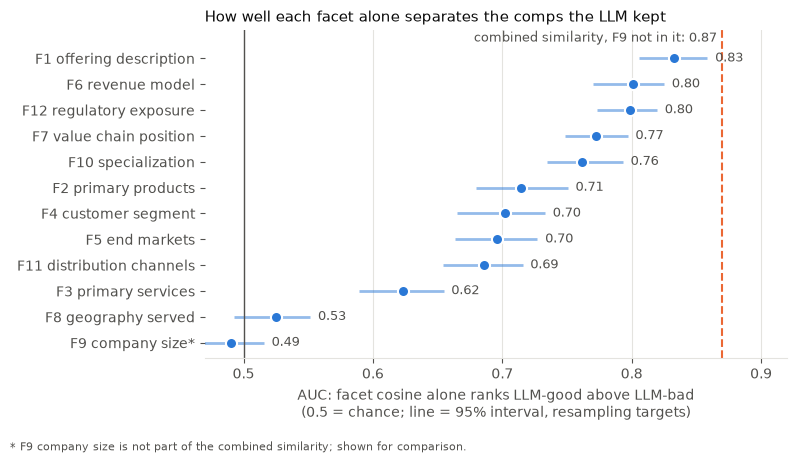

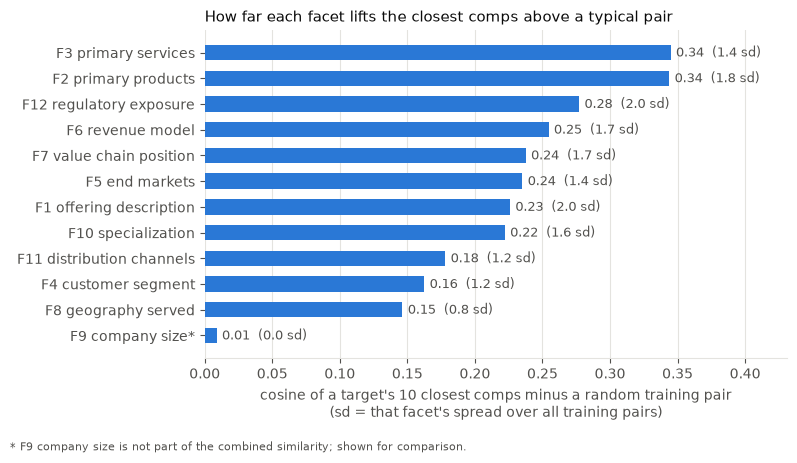

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.6))
d = summary.sort_values("auc")
yy = np.arange(len(d))
ax.hlines(yy, d["ci_low"], d["ci_high"], color=BLUE, lw=2, alpha=0.5)
ax.plot(d["auc"], yy, "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.axvline(0.5, color=INK2, lw=1)
ax.axvline(point["combined"], color=ORANGE, lw=1.5, ls="--")
ax.text(point["combined"] - 0.004, len(d) - 0.2, f"combined similarity, F9 not in it: {point['combined']:.2f}", color=INK2, ha="right", va="center", fontsize=9)
ax.set_ylim(-0.6, len(d) + 0.1)
ax.set_xlim(0.47, 0.92)
for k, v in zip(yy, d["auc"]):
    ax.text(d["ci_high"].iloc[k] + 0.006, k, f"{v:.2f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(yy, d["label"])
ax.set_xlabel("AUC: facet cosine alone ranks LLM-good above LLM-bad\n(0.5 = chance; line = 95% interval, resampling targets)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
ax.set_title("How well each facet alone separates the comps the LLM kept", loc="left", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.01, 0.01, FOOTNOTE, fontsize=8, color=INK2)
fig.savefig(FACET_OUT / "facet_separation.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.6))
d = summary.sort_values("cosine_lift")
yy = np.arange(len(d))
ax.barh(yy, d["cosine_lift"], color=BLUE, height=0.6)
for k, (v, s_) in enumerate(zip(d["cosine_lift"], d["lift_in_sd"])):
    ax.text(v + 0.004, k, f"{v:.2f}  ({s_:.1f} sd)", va="center", fontsize=9, color=INK2)
ax.set_yticks(yy, d["label"])
ax.set_xlim(0, d["cosine_lift"].max() * 1.25)
ax.set_xlabel("cosine of a target's 10 closest comps minus a random training pair\n(sd = that facet's spread over all training pairs)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
ax.set_title("How far each facet lifts the closest comps above a typical pair", loc="left", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.01, 0.01, FOOTNOTE, fontsize=8, color=INK2)
fig.savefig(FACET_OUT / "facet_lift_top10.png", dpi=150)
plt.show()

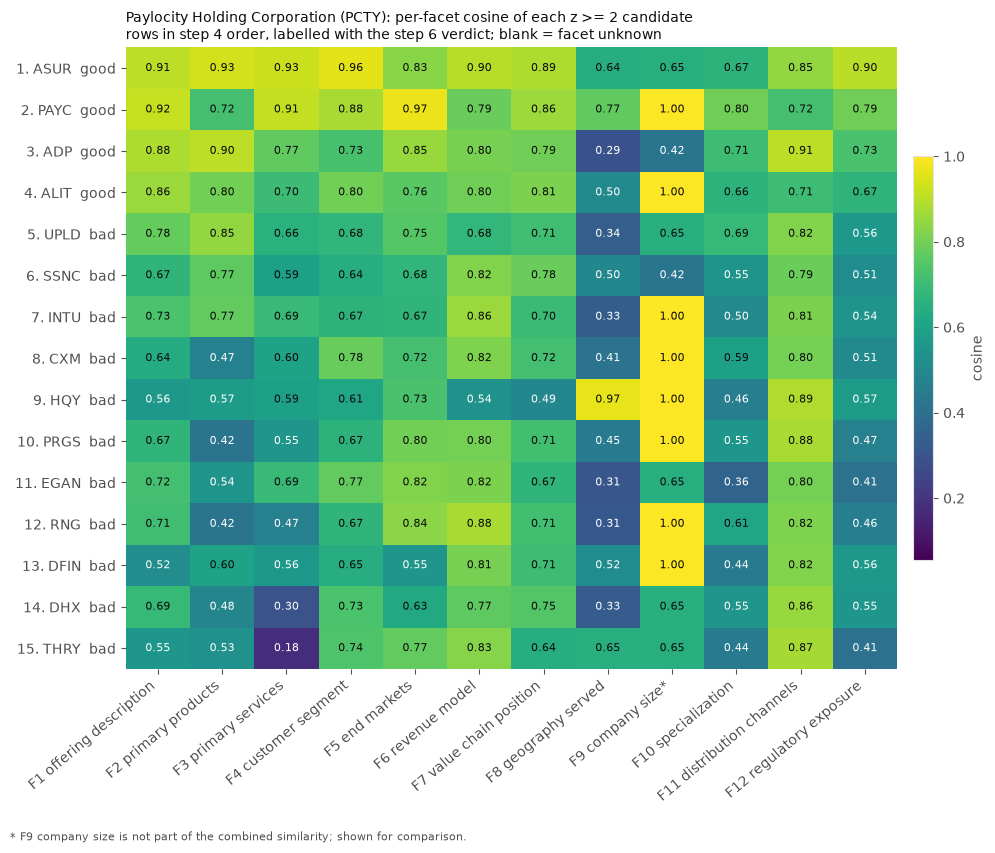

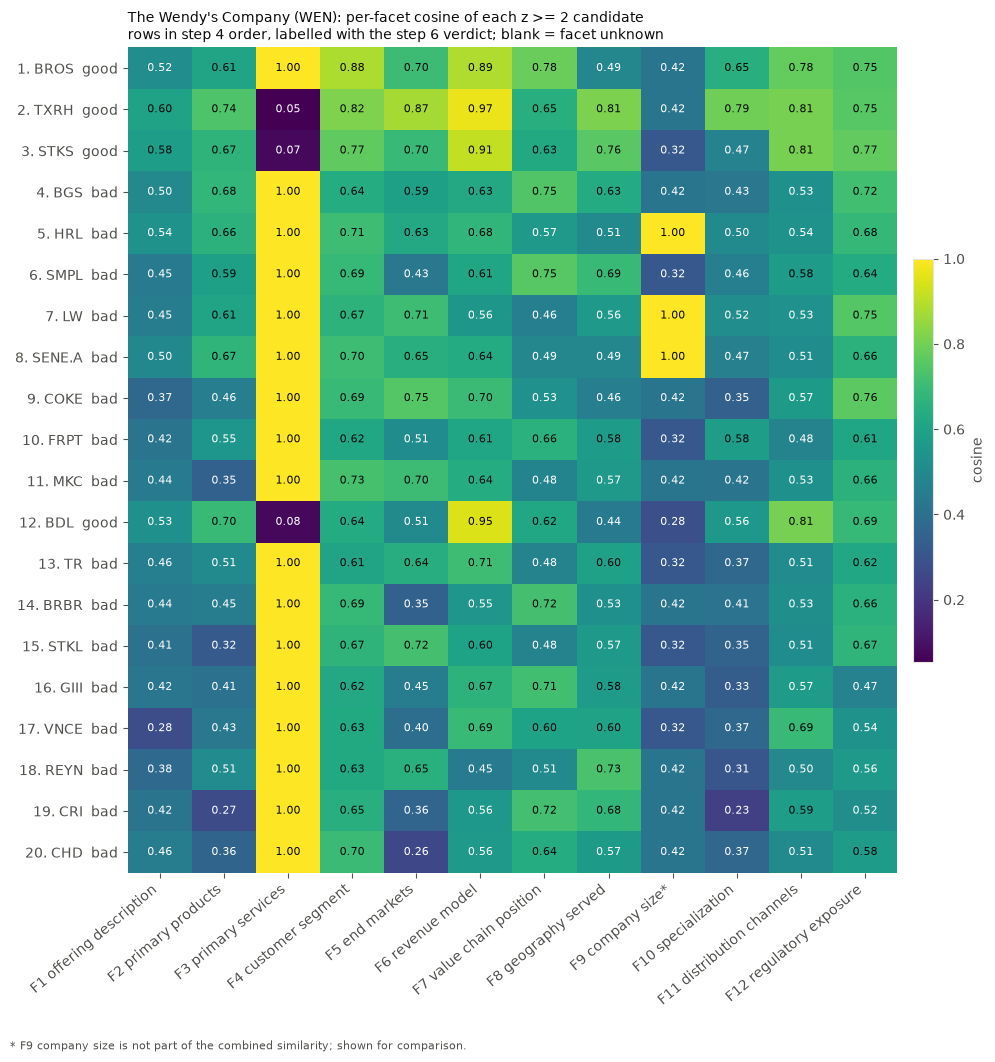

wrote outputs-local\comps_pilot_targets\facet_contribution\20261027T204930Z


In [22]:
ramp = plt.get_cmap("viridis").copy()
ramp.set_bad("#efeeea")
verdict = {(t, c): s_ for t, c, s_ in zip(judged["target"], judged["comp"], judged["score"])}
cand_z2 = ranking[ranking["z_ge_2"]]
mats = {t: pair_facets(cand_z2[cand_z2["target"] == id_of[t]].sort_values("rank")) for t in GOLDEN}
vmin = min(np.nanmin(m.to_numpy()) for m in mats.values())
vmax = max(np.nanmax(m.to_numpy()) for m in mats.values())
word = {1: "good", 0: "bad"}
for t in GOLDEN:
    rows = cand_z2[cand_z2["target"] == id_of[t]].sort_values("rank")
    M = mats[t].to_numpy()
    names = [f"{int(r)}. {info.loc[c, 'target_ciq_ticker']}  {word.get(verdict.get((id_of[t], c)), 'not judged')}"
             for r, c in zip(rows["rank"], rows["comp"])]
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(rows) + 2.2))
    im = ax.imshow(np.ma.masked_invalid(M), cmap=ramp, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if (M[i, j] - vmin) / (vmax - vmin) < 0.55 else INK)
    ax.set_xticks(range(len(FACETS)), [LABEL[n] for n in FACETS], rotation=40, ha="right")
    ax.set_yticks(range(len(rows)), names)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.set_title(f"{info.loc[id_of[t], 'target_company_name']} ({t}): per-facet cosine of each z >= 2 candidate\n"
                 f"rows in step 4 order, labelled with the step 6 verdict; blank = facet unknown", loc="left", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="cosine")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.text(0.01, 0.005, FOOTNOTE, fontsize=8, color=INK2)
    fig.savefig(FACET_OUT / f"facet_heatmap_{t}.png", dpi=150)
    plt.show()
print("wrote", FACET_OUT.relative_to(ROOT))

**Results, facets (this split; 4,996 judged pairs from 373 targets).**
- **Separation:** the combined similarity (without F9) has an AUC of 0.87. Offering description (F1) separates best alone at 0.83, then revenue model (F6) and regulatory exposure (F12) at 0.80, value chain position (F7) 0.77 and specialization (F10) 0.76. Primary services (F3) is 0.62, geography (F8) 0.53, and **company size (F9) 0.49, which is chance**.
- **Lift of the top 10:** primary services and primary products (F3, F2) lift the closest comps most (0.34 each), then regulatory exposure (0.28). Geography lifts little (0.15) and **company size not at all (0.01, 0.0 sd)**. Products and services get a comp into the top 10 but separate poorly once it is on the shortlist; offering description does the opposite.
- **Size as text behaves like a category match:** in the WEN heatmap its cosines are 1.00 for three candidates and 0.28-0.42 for the rest. Section 8 tests size as a category directly.
- **Shared "none" inflates two facets.** Primary products (F2) and primary services (F3) are "none" for 15% and 23% of training firms (no products, or no services), and a "none" matched with a "none" is an exact 1.00. Those pairs are 13% and 19% of the top-10 pairs. WEN shows it plainly: its F3 is "none", so it matches 17 of its 20 candidates exactly (1.00), and only one of those 17 (BROS) was judged good, while three of its four good comps (TXRH, STKS, BDL) list real services and score 0.05-0.08. Without them the lift falls from 0.34 to 0.29 for both (2.1 and 1.7 sd), still among the highest but no longer clearly the top. (`cosine_lift_excl_shared_none` and `pct_top10_pairs_both_none` in `facet_summary.csv`; the separation AUCs were not recomputed without them.)
- These show what moves the embedding score, and the judge reads the same facet text, so they are not independent evidence that a facet matters for valuation.

## 8. What does company size (F9) do?

The earlier split stratified on size, and size is left out of the embedding similarity, so its effect was never tested. Here the split is on SIC2 and size varies freely, so three questions can be asked of the training firms. All three are development views on the training set; the holdout is not touched.

1. **Error by size.** Median absolute % error of the main comp rules, by size category, and the median EV/EBITDA of each category.
2. **Does size agreement signal a better comp?** For each z >= 2 candidate pair, the gap in size category (0 = the same category, 3 = small against among the largest). The share the LLM kept as good, and how far apart the two EV/EBITDA multiples are, by gap.
3. **What if size were used?** The cosine comps restricted to the same size category, or within one category, scored against the unrestricted comps on the same targets.

Size categories are coarse and the small and unknown categories are thin (the counts are in the labels), so read the small ones as anecdotes. EV/EBITDA is read here only to score results, as in section 6.

In [23]:
SIZE_ORDER = ["small", "mid-sized", "large", "among the largest"]
SIZE_ALL = SIZE_ORDER + [sp.SIZE_UNKNOWN]
size = split.set_index("IQ_COMPANY_ID")["size_stratum"]
SIZE_OUT = WRITE_OUT / "size_effect" / RUN
SIZE_OUT.mkdir(parents=True, exist_ok=True)

# 1. error by size category
by_size = pd.DataFrame({"training firms": size[training].value_counts(),
                        "median EV/EBITDA": ev[training].groupby(size[training]).median()}).reindex(SIZE_ALL)
SIZE_RULES = [NO_MATCH, "cosine z ≥ 2, similarity-weighted mean", LLM_RULE, DIRECT_RULE]
pt = per_target[per_target["comp rule"].isin(SIZE_RULES)].assign(
    size=lambda d: d["IQ_COMPANY_ID"].map(size), ape=lambda d: d["error %"].abs())
err_size = pt.pivot_table(index="size", columns="comp rule", values="ape", aggfunc="median").reindex(SIZE_ALL)[SIZE_RULES]
err_size.insert(0, "training firms", by_size["training firms"])
err_size.insert(1, "median EV/EBITDA", by_size["median EV/EBITDA"])
err_size.round(1).to_csv(SIZE_OUT / "error_by_size.csv")
print("median absolute % error by company size (F9):")
display(err_size.round(1))

# 2. size gap vs the LLM's verdict and vs how far apart the two multiples are
ordv = size.map({s: i for i, s in enumerate(SIZE_ORDER)})
mult = ev.where(ev > 0)
pairs = ranking[ranking["z_ge_2"]][["target", "comp", "similarity"]].copy()
pairs["gap"] = (pairs["target"].map(ordv) - pairs["comp"].map(ordv)).abs()
pairs["multiple_gap_pct"] = 100 * (np.exp(np.log(pairs["comp"].map(mult) / pairs["target"].map(mult)).abs()) - 1)
pairs = pairs.merge(judged[["target", "comp", "score"]], on=["target", "comp"], how="left")
gap_tbl = pairs.dropna(subset=["gap"]).groupby("gap").agg(
    pairs=("comp", "size"), judged=("score", "count"), pct_good=("score", lambda s: 100 * s.mean()),
    median_multiple_gap_pct=("multiple_gap_pct", "median"))
gap_tbl.round(1).to_csv(SIZE_OUT / "size_gap.csv")
jj = pairs.dropna(subset=["gap", "score"])
print("z >= 2 candidate pairs by how many size categories apart target and comp are:")
display(gap_tbl.round(1))
print(f"AUC of 'same size' for the LLM's good comps (0.5 = no signal): "
      f"{auc(-jj['gap'].to_numpy(float), jj['score'].astype(int).to_numpy()):.3f} on {len(jj)} judged pairs")

# 3. what if comps had to match size?
def restrict(df, max_gap):
    g = (df["target"].map(ordv) - df["comp"].map(ordv)).abs()
    return df[g <= max_gap]

rows = []
for label, base_pairs in [("cosine z ≥ 2", ranking[ranking["z_ge_2"]]), ("cosine top 10", ranking[ranking["in_top_k"]])]:
    est = {"any size": vl.estimate(base_pairs, ev, weight="similarity"),
           "within 1 category": vl.estimate(restrict(base_pairs, 1), ev, weight="similarity"),
           "same category": vl.estimate(restrict(base_pairs, 0), ev, weight="similarity")}
    common = est["same category"].index
    for cap, e in est.items():
        ape = vl.errors(e, actual)["error %"].abs()
        rows.append({"rule": label + ", similarity-weighted mean", "comps allowed": cap, "targets": len(e),
                     "median abs % error": ape.median(), "same targets as 'same category'": ape.reindex(common).median(),
                     "median comps": e["comps"].median()})
restricted = pd.DataFrame(rows)
restricted.round(2).to_csv(SIZE_OUT / "size_restriction.csv", index=False)
display(restricted.round(2))

median absolute % error by company size (F9):


comp rule,training firms,median EV/EBITDA,no matching (median of the other training firms),"cosine z ≥ 2, similarity-weighted mean","LLM good comps (from z ≥ 2), similarity-weighted mean","LLM suggests directly (no embeddings), mean"
size,,,,,,
small,10,9.1,51.2,39.8,46.2,47.8
mid-sized,114,10.1,33.3,34.3,31.5,32.8
large,202,11.0,31.9,28.7,29.3,27.3
among the largest,45,10.4,27.6,24.0,27.8,31.5
unknown,2,12.4,17.0,15.0,18.3,25.9


z >= 2 candidate pairs by how many size categories apart target and comp are:


,pairs,judged,pct_good,median_multiple_gap_pct
gap,,,,
0.0,2090,2090,11.4,51.8
1.0,2435,2435,12.6,52.0
2.0,425,425,8.9,59.7
3.0,12,12,25.0,66.0


AUC of 'same size' for the LLM's good comps (0.5 = no signal): 0.498 on 4962 judged pairs


,rule,comps allowed,targets,median abs % error,same targets as 'same category',median comps
0,"cosine z ≥ 2, similarity-weighted mean",any size,373,29.58,29.58,13.0
1,"cosine z ≥ 2, similarity-weighted mean",within 1 category,371,29.18,29.20,12.0
2,"cosine z ≥ 2, similarity-weighted mean",same category,355,32.07,32.07,6.0
3,"cosine top 10, similarity-weighted mean",any size,373,28.82,28.83,10.0
4,"cosine top 10, similarity-weighted mean",within 1 category,371,28.06,28.13,10.0
5,"cosine top 10, similarity-weighted mean",same category,352,32.27,32.27,5.0


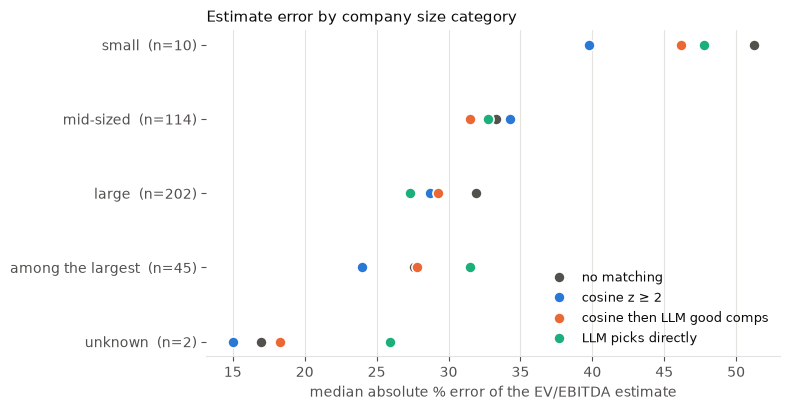

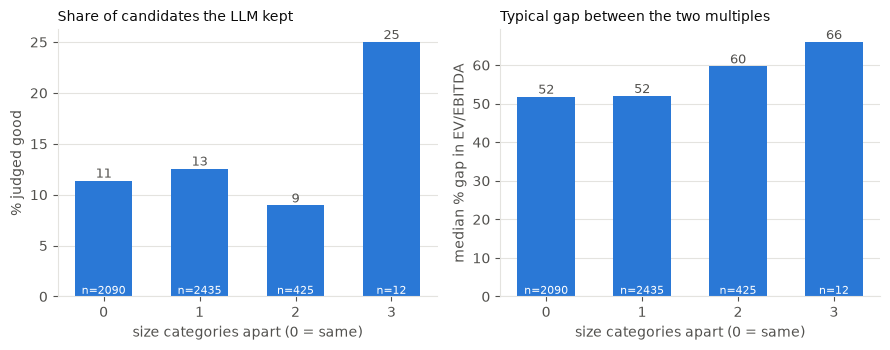

wrote outputs-local\comps_pilot_targets\size_effect\20261027T204930Z


In [24]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = err_size.dropna(subset=["training firms"])
yy = np.arange(len(d))
style = {NO_MATCH: ("no matching", INK2, "o"), "cosine z ≥ 2, similarity-weighted mean": ("cosine z ≥ 2", BLUE, "o"),
         LLM_RULE: ("cosine then LLM good comps", ORANGE, "o"), DIRECT_RULE: ("LLM picks directly", "#1baf7a", "o")}
for rule, (nm, col, mk) in style.items():
    ax.plot(d[rule], yy, mk, color=col, ms=8, mec="white", mew=1.2, label=nm)
ax.set_yticks(yy, [f"{s}  (n={int(n)})" for s, n in zip(d.index, d["training firms"])])
ax.invert_yaxis()
ax.set_xlabel("median absolute % error of the EV/EBITDA estimate")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s_ in ("top", "right", "left"):
    ax.spines[s_].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("Estimate error by company size category", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(SIZE_OUT / "error_by_size.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, col, ttl, unit in [(axes[0], "pct_good", "Share of candidates the LLM kept", "% judged good"),
                           (axes[1], "median_multiple_gap_pct", "Typical gap between the two multiples", "median % gap in EV/EBITDA")]:
    ax.bar(gap_tbl.index.astype(int), gap_tbl[col], color=BLUE, width=0.6)
    for g, v, n in zip(gap_tbl.index.astype(int), gap_tbl[col], gap_tbl["pairs"]):
        ax.text(g, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
        ax.text(g, 0, f"n={int(n)}", ha="center", va="bottom", fontsize=8, color="white")
    ax.set_xticks(gap_tbl.index.astype(int))
    ax.set_xlabel("size categories apart (0 = same)")
    ax.set_ylabel(unit)
    ax.set_title(ttl, loc="left", fontsize=10)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
fig.tight_layout()
fig.savefig(SIZE_OUT / "size_gap.png", dpi=150)
plt.show()
print("wrote", SIZE_OUT.relative_to(ROOT))

**Results, company size (this split; training firms, development only).**
- **Error by size:** it falls as firms get bigger, for every rule. Cosine z ≥ 2 is 39.8% for small firms (n=10), 34.3% for mid-sized (114), 28.7% for large (202) and 24.0% for among the largest (45); no matching is 51.2%, 33.3%, 31.9% and 27.6%. The median EV/EBITDA barely moves with size (9.1, 10.1, 11.0, 10.4), so size is not a level effect.
- **Size gap and the LLM's verdict:** none. The AUC of "same size" for the LLM's good comps is 0.498 (chance); 11%, 13% and 9% of candidates are kept at gaps of 0, 1 and 2 categories (the 25% at a gap of 3 is 12 pairs).
- **Size gap and the multiples:** the typical gap between the two EV/EBITDA multiples is 52% for same-size and one-apart pairs, 60% at two categories and 66% at three (425 and 12 pairs). Size matters only for large gaps.
- **Restricting comps by size:** the same category hurts (cosine z ≥ 2: 32.1% against 29.6% unrestricted, with 6 comps against 13 and 18 fewer targets). Within one category is about half a point better (29.2%; top 10: 28.1% against 28.8%), which is within noise.
- **So:** F9 is not a useful comp filter on this data beyond excluding extreme size gaps. If it enters the similarity, a small weight is more defensible than a hard match. The small and unknown categories are too thin to read.

## 9. Choosing two targets for the golden set

The golden set is a small set of target-comp pairs labeled by hand, to calibrate the comp rules. It takes **two of the ten showcase targets above**. What the table below is for, per target:

- **Business structure (from the pilot):** a one-business target has one thing to compare comps to; a multi-business one needs a decision first, whether comps are labeled for the whole company or for one line.
- **Whether the routes find comps:** a target with no LLM-good comp and few direct picks gives little to label or compare.
- **Labeling load:** the pool to label is the union of the z ≥ 2 cosine candidates and the direct LLM picks (the pooled-labeling design: cosine alone would only measure the shortlist it came from).
- **Disagreement between routes:** direct picks outside the cosine shortlist, and candidates the LLM rejected, are where a human label is most informative.

Rank, z, the LLM's verdicts and EV/EBITDA are left out of what a labeler sees; the multiples are not shown here at all. **Current pick: PCTY and WEN** (✓ below). Both are one-business targets (the pilot's related-products tests) with clear positives: the LLM kept 4 of PCTY's 15 candidates and 4 of WEN's 20, and its direct picks fall inside the cosine shortlist for WEN and all but one (BBSI) for PCTY. WEN has the longer list of the two, so a human label says the most about the judge's precision there. Change `GOLDEN` in section 7 and re-run to change it.

In [25]:
PILOT = {   # the pilot's reading of each target (business_structure_eval.ipynb, 2026-10-27)
    "PCTY": ("related products", "one business (1 line)"),
    "WEN": ("related products", "one business (1 line)"),
    "CSL": ("completed exit", "one business (1 line); 3 exited"),
    "AFG": ("completed exit", "one business (1 line); 2 exited"),
    "AZZ": ("completed exit", "one business (2 lines, 1 group); 1 exited"),
    "NWSA": ("current multi-business", "multiple businesses (4 lines, 4 groups)"),
    "BOC": ("current multi-business", "multiple businesses (4 lines, 4 groups)"),
    "BBCP": ("current multi-business", "multiple businesses (3 lines, 2 groups)"),
    "BUKS": ("current multi-business", "multiple businesses (4 lines, 2 groups)"),
    "SNFC.A": ("current multi-business", "multiple businesses (3 lines, 3 groups)"),
}
assert set(PILOT) == set(SHOWCASE), set(PILOT) ^ set(SHOWCASE)

z2_pairs = ranking[ranking["z_ge_2"]]
rows = []
for t in SHOWCASE:
    tid = id_of[t]
    cosine = set(z2_pairs.loc[z2_pairs["target"] == tid, "comp"])
    kept = set(judged.loc[(judged["target"] == tid) & (judged["score"] == 1), "comp"])
    picks = set(direct.loc[direct["target"] == tid, "comp"])
    rows.append({"ticker": t, "company": info.loc[tid, "target_company_name"],
                 "SIC industry": info.loc[tid, "target_primary_sic_industry"],
                 "size (F9)": split.set_index("IQ_COMPANY_ID").loc[tid, "size_stratum"],
                 "picked to test": PILOT[t][0], "pilot split": PILOT[t][1],
                 "z>=2 candidates": len(cosine), "LLM kept as good": len(kept), "direct LLM picks": len(picks),
                 "direct picks outside the shortlist": len(picks - cosine),
                 "pool to label": len(cosine | picks),
                 "golden pick": "✓" if t in GOLDEN else ""})
target_choice = pd.DataFrame(rows).set_index("ticker")
GOLDEN_OUT = WRITE_OUT / "golden_set" / RUN
GOLDEN_OUT.mkdir(parents=True, exist_ok=True)
target_choice.to_csv(GOLDEN_OUT / "target_choice.csv")
print(f"golden-set pick: {', '.join(GOLDEN)}; wrote {(GOLDEN_OUT / 'target_choice.csv').relative_to(ROOT)}")
target_choice

golden-set pick: PCTY, WEN; wrote outputs-local\comps_pilot_targets\golden_set\20261027T204930Z\target_choice.csv


,company,SIC industry,size (F9),picked to test,pilot split,z>=2 candidates,LLM kept as good,direct LLM picks,direct picks outside the shortlist,pool to label,golden pick
ticker,,,,,,,,,,,
PCTY,Paylocity Holding Corporation,"Computer Programming, Data Processing, And Other Computer Related Services",large,related products,one business (1 line),15,4,5,1,16,✓
WEN,The Wendy's Company,Eating Places,among the largest,related products,one business (1 line),20,4,3,0,20,✓
CSL,Carlisle Companies Incorporated,Asphalt Paving And Roofing Materials,large,completed exit,one business (1 line); 3 exited,5,2,3,0,5,
AFG,"American Financial Group, Inc.","Fire, Marine, and Casualty Insurance",large,completed exit,one business (1 line); 2 exited,19,5,5,0,19,
BOC,Boston Omaha Corporation,Advertising,mid-sized,current multi-business,"multiple businesses (4 lines, 4 groups)",10,3,6,3,13,
NWSA,News Corporation,"Newspapers: Publishing, or Publishing and Printing",among the largest,current multi-business,"multiple businesses (4 lines, 4 groups)",7,1,4,1,8,
AZZ,AZZ Inc.,"Coating, Engraving, And Allied Services",large,completed exit,"one business (2 lines, 1 group); 1 exited",14,0,1,0,14,
BBCP,"Concrete Pumping Holdings, Inc.",Construction Special Trade Contractors,among the largest,current multi-business,"multiple businesses (3 lines, 2 groups)",14,0,2,2,16,
BUKS,Butler National Corporation,Management Services,small,current multi-business,"multiple businesses (4 lines, 2 groups)",11,3,5,1,12,


## 10. To do: fix the "not applicable" facets (not done in this notebook)

**What is wrong.** The facet fill marks a facet `not_applicable` for some businesses that do have the thing (Wendy's primary services is "none", although it runs restaurants and franchising), and the similarity embeds "none" as text, so two firms with "none" match exactly (cosine 1.00). Section 7 measures it: 15% (F2) and 23% (F3) of firms are "none", those pairs are 13% and 19% of the top-10 pairs, and WEN matches 17 of its 20 candidates on F3, 16 of them judged bad. It has been in the step 4 similarity since 2026-10-25 (`NOT_APPLICABLE_TEXT` in `v0/candidates.py`); the per-facet charts are what made it visible.

**Stopgap, not applied here.** Treat `not_applicable` as missing, like unknown: `facet_texts` would return `None` for it, so a pair where both firms have "none" skips that facet instead of scoring 1.00, and the other facets carry the comparison. No re-fill is needed. The judge re-runs for the targets whose shortlist changes (at most about $0.50 on the last run's cost); the direct picks do not use similarity and do not change. It changes the method, so it needs a team decision. The 2026-10-27 plan was to do this next.

**Fix at the source.** Tighten the facet prompt so a business that has products or services is not marked not applicable, bump `PROMPT_VERSION`, and re-run the fill for all 533 companies (about $0.50 for the fill, the README's figure), then the judge and the direct picks (about $1.1 on the last runs). The facets table keeps only the current prompt version, so a partial re-fill is not possible, and other facets will drift too (revenue model agreed between two earlier prompt versions for only 62% of companies). Data stays collected by code, never corrected by hand. Check afterwards: re-run sections 7 and 9 and look at the F3 column of the WEN heatmap.

Costs are the project's recorded figures for earlier runs, not new quotes.